# Who gets the good Batman stories?

Which writers, artists, and characters turn up in BatChat's favorites? Which series have the strongest showing? And how much changes when we compare books from the same decade?

These are **740 stories ranked by Matt Lazorwitz and Will Nevin** on [BatChat](https://comicsxf.com/batchat-rankings/). **Rank 1 is best. Lower is better throughout.** Start with the leaderboards, then look at eras, creative teams, and plots.

By [Dan Ofer](https://scholar.google.com/citations?user=uDx2ItYAAAAJ). [Dataset](https://www.kaggle.com/datasets/danofer/batchat-batman-rankings) · [Code and sources](https://github.com/ddofer/BatRank).

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

candidates = [Path.cwd(), Path.cwd().parent]
candidates += [p.parents[2] for p in Path('/kaggle/input').glob('**/data/processed/stories.csv')]
DATA_ROOT = next(p for p in candidates if (p/'data/processed/stories.csv').exists())
sys.path.insert(0, str(DATA_ROOT))
from scripts.analysis import load_data, split_set, save_figure, COLORS, ROLES
ROOT, REPORT, s, issues = load_data()
N = len(s)
s['preference'] = 1-s.rank_percentile
print(f'{N:,} ranked entries · {len(issues):,} issue references · snapshot {s.snapshot_date.iloc[0]}')

creators=pd.read_csv(ROOT/'data/processed/creators.csv')
credits=pd.read_csv(ROOT/'data/processed/story_creators.csv')
creator_awards=pd.read_csv(ROOT/'data/processed/creator_awards.csv')


740 ranked entries · 2,434 issue references · snapshot 2026-10-21


## Who wrote them, and when?

**Chuck Dixon leads with 34 stories**, followed by Alan Grant with 31 and Dennis O'Neil with 28. These counts describe the podcast's list, not the writers' full output.

The decade chart has a surprise: the **2020s' median rank of 300** sits close to the **1980s' 310**. There are favorites and disappointments in every era. Dots show medians; bars span the middle half of the ranks. **Farther left is better.**

<details><summary>What's included?</summary>

Writer counts use 677 stories with complete writer attribution. Co-written stories count for each writer. The decade chart uses 733 stories with a known cover year; arcs use their first issue. The 1930s have only three stories. These are selected books, not random samples of each decade.

</details>

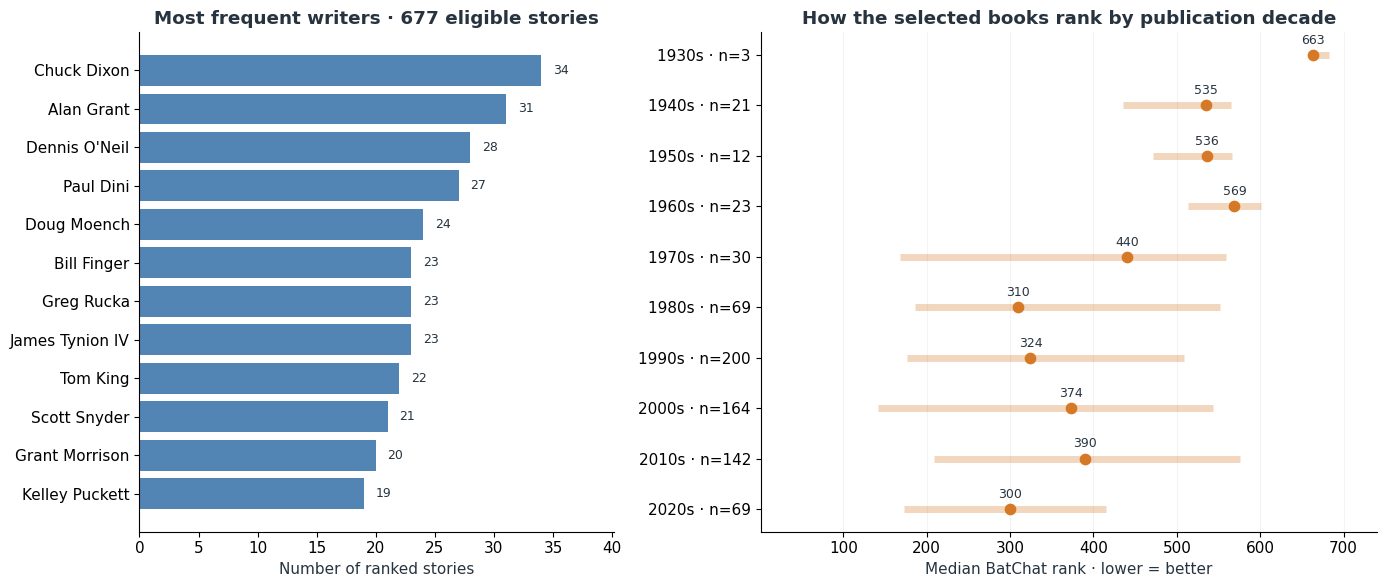

7 stories have no cover-start year. Bars on the right show the middle half, not confidence intervals.


In [2]:
writer_ids=s.loc[s.metadata_complete & s.substory_attribution_coverage.eq(1)
                 & s.narrative_credit_issue_coverage.eq(1),'story_id']
writer_links=credits[credits.credit_scope.eq('selected_narrative') & credits.role.eq('writers')
                     & credits.story_id.isin(writer_ids)]
assert not writer_links.duplicated(['story_id','creator_id']).any()
writer_profiles=writer_links.merge(s[['story_id','rank']],on='story_id',validate='many_to_one').groupby('creator_id').agg(
    readings=('story_id','nunique'),median_rank=('rank','median'))
writer_profiles=writer_profiles.merge(creators[['creator_id','name']],on='creator_id',validate='one_to_one')
writer_profiles=writer_profiles.sort_values(['readings','name'],ascending=[False,True])
writer_profiles.to_csv(REPORT/'writer_profiles.csv',index=False)
frequent=writer_profiles.head(12).iloc[::-1]

era=s.dropna(subset=['cover_year_start']).copy()
era['decade']=(era.cover_year_start//10*10).astype(int)
era_profile=era.groupby('decade')['rank'].agg(n='size',median_rank='median',
    q25=lambda v:v.quantile(.25),q75=lambda v:v.quantile(.75))
assert era_profile.n.sum()+s.cover_year_start.isna().sum()==N
era_profile.to_csv(REPORT/'rank_by_publication_decade.csv')
fig,axes=plt.subplots(1,2,figsize=(14,6),gridspec_kw={'width_ratios':[1,1.3]})
ax=axes[0]
ax.barh(frequent.name,frequent.readings,color=COLORS['blue'],alpha=.8)
for pos,count in enumerate(frequent.readings):ax.text(count+1,pos,str(count),va='center',fontsize=9)
ax.set(xlim=(0,frequent.readings.max()*1.18),xlabel='Number of ranked stories',
       title=f'Most frequent writers · {writer_links.story_id.nunique()} eligible stories')
ax=axes[1]
positions=np.arange(len(era_profile))
ax.hlines(positions,era_profile.q25,era_profile.q75,lw=5,alpha=.3,color=COLORS['orange'])
ax.scatter(era_profile.median_rank,positions,color=COLORS['orange'],s=55)
ax.set(yticks=positions,yticklabels=[f'{d}s · n={int(row.n)}' for d,row in era_profile.iterrows()],
       xlim=(1,N),xlabel='Median BatChat rank · lower = better',title='How the selected books rank by publication decade')
ax.invert_yaxis()
for pos,value in enumerate(era_profile.median_rank):ax.annotate(f'{value:.0f}',(value,pos),xytext=(0,8),textcoords='offset points',ha='center',fontsize=9)
ax.xaxis.grid(True,alpha=.15);ax.set_axisbelow(True)
fig.tight_layout();save_figure(fig,REPORT,'eda-writers-and-decades')
print(f'{s.cover_year_start.isna().sum()} stories have no cover-start year. Bars on the right show the middle half, not confidence intervals.')

## The highest- and lowest-ranked creators

Who has a run of favorites? Who keeps turning up near the bottom? Compare writers and pencilers separately. Each needs **at least five fully attributed stories**.

Boxes show the middle half of their stories. The line inside is the median; faint dots show individual stories. **Left is better.** A shared story counts for each contributor. These are results for the books BatChat chose, not career ratings.

Bruce Timm leads the eligible writers, with a median rank of **39 across five stories**. Michael Lark leads pencilers at **40.5 across six**. Several low medians belong to creators represented in highly ranked anthologies. J.M. DeMatteis has a median of **622 across nine stories**. Five stories is a small minimum; the tables show how much the ranks vary.

Raise the minimum to **ten stories**, and the leaders change to **Ed Brubaker** for writing and **Tim Sale** for pencils.

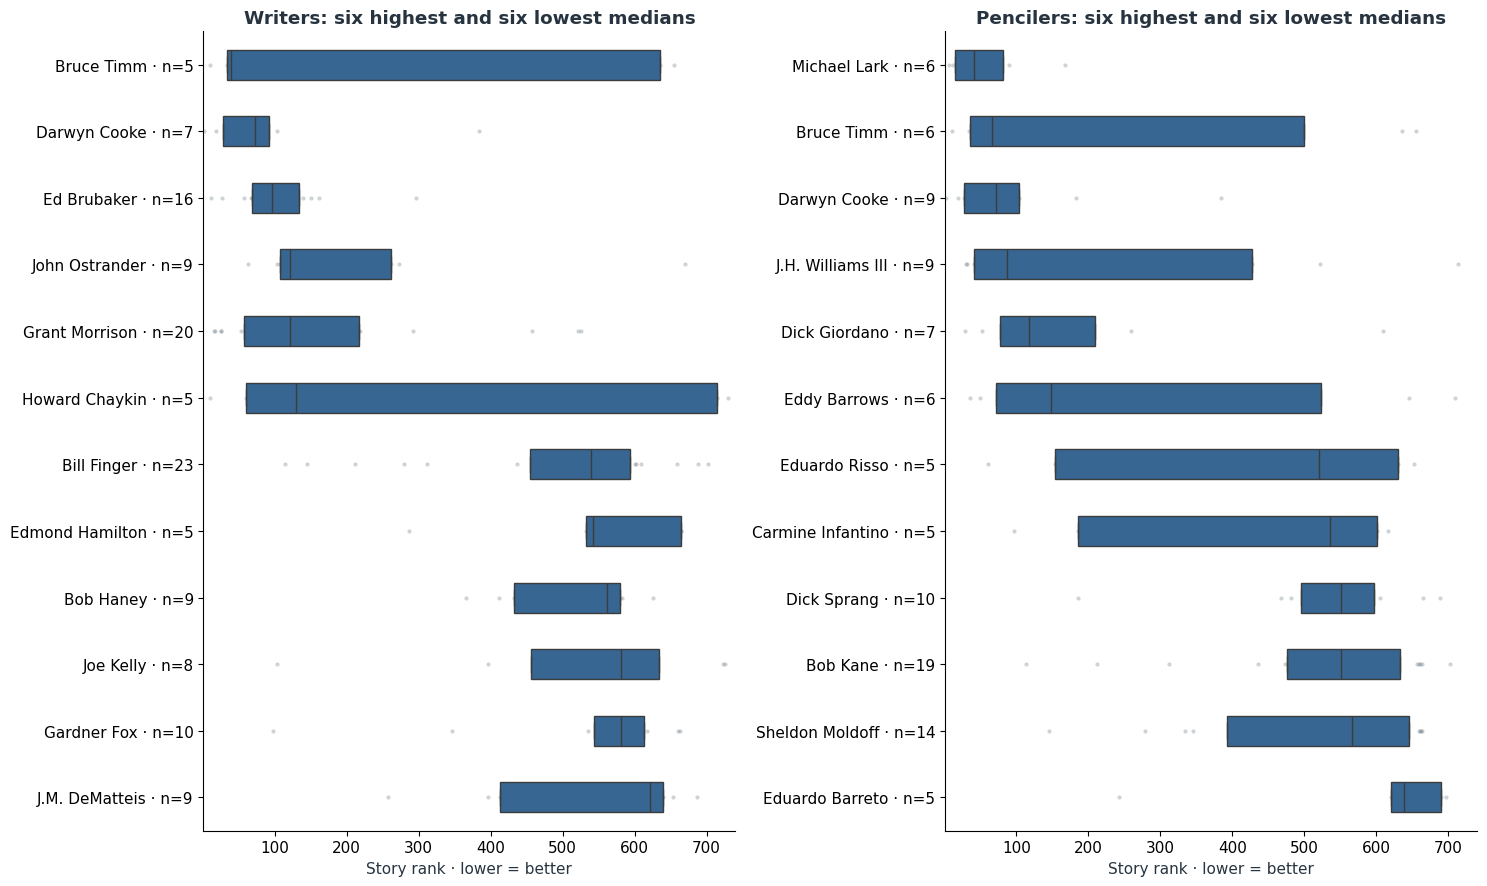

Name,Stories,Median rank,Best rank,Best story,Worst rank,Worst story
Bruce Timm,5,39.0,10,Batman: Black and White Vol.1,655,Batman: Harley & Ivy #1-3
Darwyn Cooke,7,72.0,2,Ego,384,Justice League: The New Frontier Special
Ed Brubaker,16,96.5,12,Soft Targets,296,Fearless
John Ostrander,9,121.0,63,A Savage Innocence,670,Grotesk
Grant Morrison,20,121.5,15,Batman: R.I.P.,526,The Three Ghosts of Batman
Howard Chaykin,5,130.0,10,Batman: Black and White Vol.1,730,Batman: Dark Allegiances
Matt Wagner,6,155.5,10,Batman: Black and White Vol.1,469,Faces
Jeph Loeb,13,173.0,4,The Long Halloween,615,Lord of the Ring
Greg Rucka,23,194.0,12,Soft Targets,615,Lord of the Ring
Jeff Parker,9,211.0,126,Batman ’66 V.1,326,Batman/Santa Claus: Silent Knight #1-4


Name,Stories,Median rank,Best rank,Best story,Worst rank,Worst story
Michael Lark,6,40.5,7,Some Of These Days,168,Batman: Nine Lives OGN
Bruce Timm,6,65.5,10,Batman: Black and White Vol.1,655,Batman: Harley & Ivy #1-3
Darwyn Cooke,9,72.0,2,Ego,384,Justice League: The New Frontier Special
J.H. Williams III,9,87.0,30,Six Fingers,713,Chasing Clay
Dick Giordano,7,118.0,28,To Kill a Legend,610,Batman: Hollywood Knights #1-3
Eddy Barrows,6,147.5,35,Cheer,710,Grounded
John Romita Jr.,5,153.0,33,The Dark Knight Returns: The Last Crusade,728,Superman: Year One #3
Matt Wagner,6,155.5,10,Batman: Black and White Vol.1,469,Faces
Lee Garbett,5,161.0,26,Final Crisis,219,Batgirl Rising- Point of New Origin
Álvaro Martínez Bueno,6,169.5,49,Rise of the Batmen,480,Batman & Robin Eternal #1-26


Name,Stories,Median rank,Best rank,Best story,Worst rank,Worst story
Michael Lark,6,40.5,7,Some Of These Days,168,Batman: Nine Lives OGN
Darwyn Cooke,7,72.0,2,Ego,384,Justice League: The New Frontier Special
J.H. Williams III,6,75.5,31,Beautiful People,522,The Club of Heroes
Bruce Timm,7,92.0,10,Batman: Black and White Vol.1,655,Batman: Harley & Ivy #1-3
Klaus Janson,6,120.0,8,The Dark Knight Returns,193,DC Pride 2021
Norm Breyfogle,9,120.0,22,Knightfall Part 1: The Broken Bat,481,Ecstasy
Drew Geraci,5,122.0,26,Final Crisis,314,I was the Love Slave of a Planet Based Killer
Eber Ferreira,5,140.0,35,Cheer,646,Perpetual Motion
Raúl Fernández,6,169.5,49,Rise of the Batmen,480,Batman & Robin Eternal #1-26
Tim Sale,11,173.0,4,The Long Halloween,703,The Wedding


Name,Stories,Median rank,Best rank,Best story,Worst rank,Worst story
Tatjana Wood,5,119.0,20,The Garden of Earthly Delights,222,Riddles
Nathan Fairbairn,6,129.0,25,Leviathan Strikes,355,Superheavy
Adriano Lucas,7,140.0,35,Cheer,369,New Year’s Evil V.2 #1
Matt Hollingsworth,13,168.0,24,Half a Life,737,Batman: Curse of the White Knight #1-8
Tony Aviña,11,170.0,26,Final Crisis,675,Golden Dawn
Marissa Louise,5,193.0,65,Sword of Azrael (2022) #1-6,557,"Harley Quinn: The Animated Series- The Eat, Bang, Kill Tour #1-6"
James Sinclair,6,201.0,44,Blink,549,Terror
Dave Stewart,28,237.0,19,The New Frontier,630,A Grim Knight in Gotham
José Villarrubia,6,245.0,53,Batman: The Return of Bruce Wayne #1-6,703,The Wedding
Romulo Fajardo Jr.,5,250.0,184,Batman: Eternal V.3,590,The Princess and the Knight


Name,Stories,Median rank,Best rank,Best story,Worst rank,Worst story
Kurt Hathaway,5,107.0,44,Blink,549,Terror
Sean Konot,7,132.0,27,Anodyne,704,The Fishy Laugh
Ariana Maher,5,193.0,86,DC Pride 2022,392,Gotham Villains 80th Anniversary Giant
Clem Robins,17,194.0,12,Soft Targets,731,The Surrogate
Tom Napolitano,16,223.0,87,Batman: Black and White V.4,717,Fear of the Dark
Richard Starkings,28,231.0,4,The Long Halloween,718,"Batman: The Blue, The Grey, and the Bat"
John Workman,17,235.0,10,Batman: Black and White Vol.1,728,Superman: Year One #3
Todd Klein,70,251.0,1,Year One,734,Batman: White Knight #1-8
Troy Peteri,13,254.0,40,Father’s Day,709,Tales from the Dark Multiverse: Batman- Hush
Willie Schubert,36,287.5,24,Half a Life,697,Knightquest: The Search


Name,Stories,Median rank,Best rank,Best story,Worst rank,Worst story
Mark Chiarello,12,66.0,2,Ego,585,Batman: Noel OGN
E. Nelson Bridwell,7,147.0,14,Strange Apparitions,711,The Last Batman Story–?
Matt Idelson,20,172.0,12,Soft Targets,710,Grounded
Nachie Castro,19,194.0,12,Soft Targets,714,Brothers in Blood
Aniz Ansari,9,223.0,38,Batman ’66: The Lost Episode,409,Injustice: Gods Among Us Vol.2
Michael McCalister,5,224.0,86,DC Pride 2022,271,Hammer of Justice
Chuck Kim,12,231.5,4,The Long Halloween,540,Werewolf
Rob Levin,6,249.5,69,Everyday.,676,Manslaughter
Dan Raspler,27,255.0,29,Batman: The Cult #1-4,629,Robin Lives!
Jim Chadwick,24,262.0,38,Batman ’66: The Lost Episode,674,Injustice: Gods Among Us Year 4 Vol. 2


In [3]:
import seaborn as sns

eligible_ids = s.loc[s.metadata_complete & s.substory_attribution_coverage.eq(1)
                    & s.narrative_credit_issue_coverage.eq(1), 'story_id']
creator_stories = (credits.loc[credits.credit_scope.eq('selected_narrative')
                               & credits.story_id.isin(eligible_ids)]
    .merge(creators[['creator_id', 'name']], on='creator_id', validate='many_to_one')
    .merge(s[['story_id', 'title', 'rank']], on='story_id', validate='many_to_one'))
assert not creator_stories.duplicated(['story_id', 'creator_id', 'role']).any()
creator_rankings = (creator_stories.sort_values('rank').groupby(['role', 'creator_id', 'name'])
    .agg(stories=('story_id', 'nunique'), median_rank=('rank', 'median'),
         best_rank=('rank', 'first'), best_story=('title', 'first'),
         worst_rank=('rank', 'last'), worst_story=('title', 'last')).reset_index())
creator_rankings.to_csv(REPORT/'creator_rankings.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 9), sharex=True)
for ax, role, label in zip(axes, ['writers', 'pencilers'], ['Writers', 'Pencilers']):
    eligible = creator_rankings.query('role == @role and stories >= 5').sort_values('median_rank')
    extremes = pd.concat([eligible.head(6), eligible.tail(6)]).drop_duplicates('creator_id')
    labels = extremes.set_index('creator_id').apply(lambda r: f'{r["name"]} · n={r.stories}', axis=1)
    chart = creator_stories.loc[creator_stories.role.eq(role)
                               & creator_stories.creator_id.isin(extremes.creator_id)].copy()
    chart['Creator'] = chart.creator_id.map(labels)
    sns.stripplot(data=chart, x='rank', y='Creator', order=labels.tolist(), ax=ax,
                  color=COLORS['grey'], alpha=.35, size=3, jitter=False, zorder=0)
    sns.boxplot(data=chart, x='rank', y='Creator', order=labels.tolist(), ax=ax,
                color=COLORS['blue'], whis=0, showfliers=False, width=.45)
    ax.set(title=f'{label}: six highest and six lowest medians',
           xlabel='Story rank · lower = better', ylabel='', xlim=(1, N))
fig.tight_layout()
save_figure(fig, REPORT, 'eda-creator-highs-lows')

from IPython.display import HTML
for role in ROLES:
    table = creator_rankings.query('role == @role and stories >= 5').sort_values('median_rank')
    display(HTML(f'<details><summary>{role.capitalize()}: all {len(table)} names with five or more stories</summary>'
        '<p>Median rank: lower is better. Best and worst examples show the range.</p>'
        +table[['name','stories','median_rank','best_rank','best_story','worst_rank','worst_story']]
        .rename(columns=lambda c: c.replace('_',' ').capitalize()).to_html(index=False, escape=True)
        +'</details>'))


## Which heroes and villains get the better stories?

Barbara Gordon's **52 featured appearances** have a median rank of **235.5**. Bruce Wayne's **479** have **379**. Many books feature both.

Below are the **15 most frequent names in each role**. Dots show median ranks; bars span the middle half. **Left is better.** The dotted line marks the median across all 682 eligible stories.

“Featured” usually means a hero, but villains can star too. “Antagonist” describes their role in that story. Neither label measures how much page time they get.

The [full cast atlas](../reports/figures/eda-gotham-atlas.png) expands this to **75 featured names and 95 antagonist names** with at least five stories. Dark patches show where their books cluster in the ranking.

<details><summary>Names, roles, and downloadable tables</summary>

We require complete character records for the selected stories. Cameos, mentions, flashbacks, and depictions are excluded. Each name counts once per story and role.

Matching names are combined across universe labels. Different aliases remain separate here, including Riddler's Nashton, Nygma, and Nigma names. Groups and unnamed characters remain too.

The [featured-cast table](../reports/featured_cast_profiles.csv) and [antagonist table](../reports/antagonist_profiles.csv) include all 531 and 1,487 names, respectively, with counts and best- and worst-ranked examples.

</details>

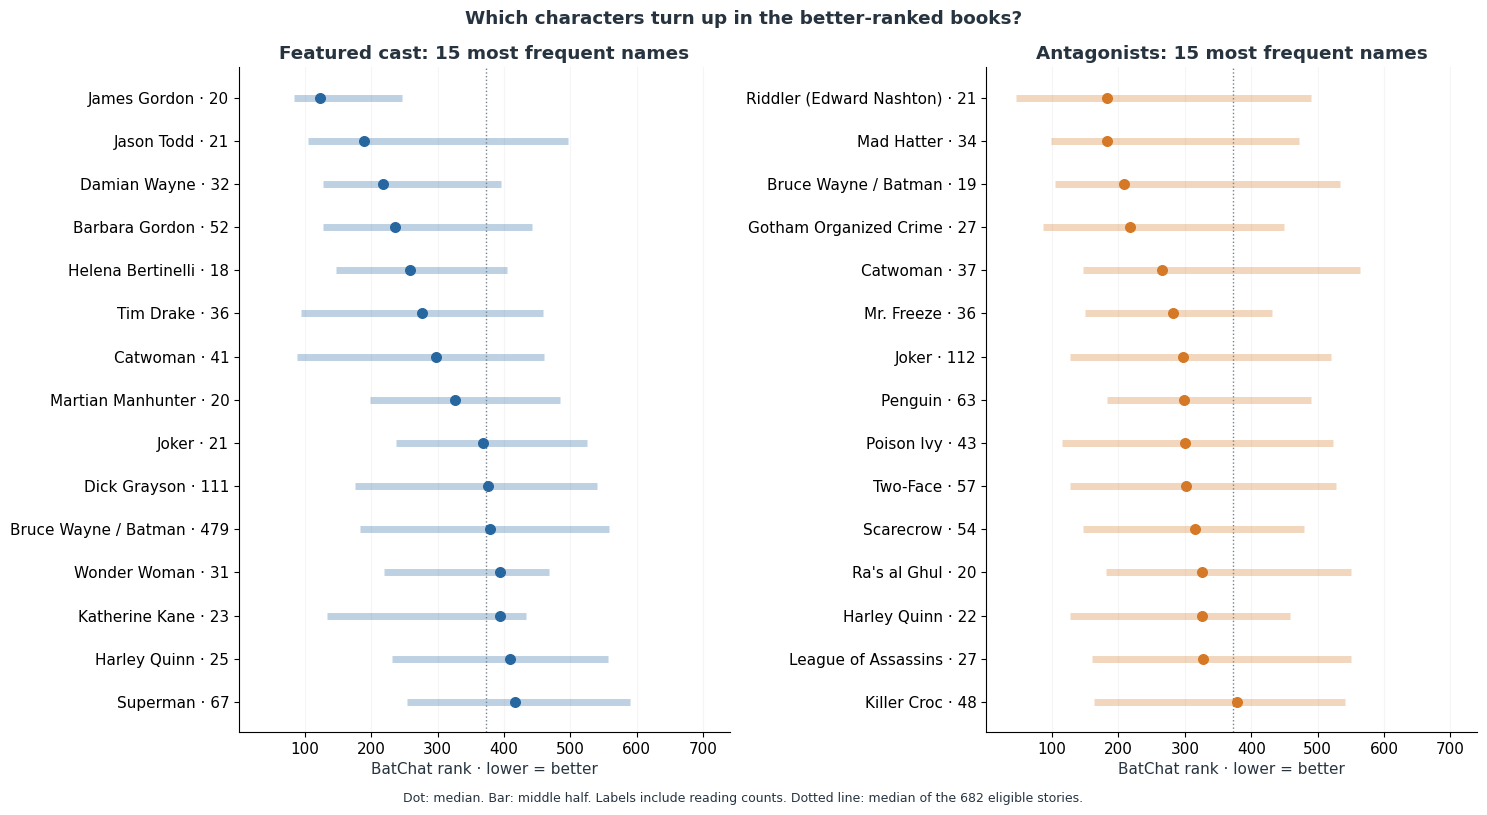

Cast entry,Stories,Median rank · lower = better,Best rank · lowest,Worst rank · highest
Norman McCay,1,13.0,13,13
Josephine MacDonald,2,18.0,12,24
Challengers of the Unknown,1,19.0,19,19
Clay,1,19.0,19,19
Flying Cloud,1,19.0,19,19
Gunner MacKay,1,19.0,19,19
John Wilson,1,19.0,19,19
Kyle Morgan,1,19.0,19,19
Lester Davis,1,19.0,19,19
Losers,1,19.0,19,19


Cast entry,Stories,Median rank · lower = better,Best rank · lowest,Worst rank · highest
Branden,1,1.0,1,1
Gillian B. Loeb,1,1.0,1,1
Johnny Viti,1,1.0,1,1
Carla Falcone,1,4.0,4,4
Donald Sullivan,1,4.0,4,4
Frankie Carbone,1,4.0,4,4
Jimmy Murphy,1,4.0,4,4
Joe Bandano,1,4.0,4,4
Kevin Kelly,1,4.0,4,4
Luca Mareli,1,4.0,4,4


1,104 antagonist entries appear only once. CSVs also include best- and worst-ranked story titles.


In [4]:
import re
clean=s[s.cast_scope.eq('selected_narratives') & s.cast_issue_coverage.eq(1)].copy()
clean['decade']=(clean.cover_year_start//10*10).astype('Int64')

def entity_associations(frame,column):
    out=frame[['story_id','rank','preference','cover_year_start',column]].copy()
    out['entity']=out[column].map(split_set)
    out=out.explode('entity').dropna(subset=['entity'])
    out['entity']=out.entity.str.replace(r' \([^()]+\)$','',regex=True)
    return out.drop_duplicates(['story_id','entity'])

antagonists=entity_associations(clean,'antagonists_entity_ids')
featured=entity_associations(clean,'featured_entity_ids')
aliases={'Jervis Tetch':'Mad Hatter','Selina Kyle':'Catwoman','Victor Fries':'Mr. Freeze',
    'Oswald Cobblepot':'Penguin','Pamela Isley':'Poison Ivy','Harvey Dent':'Two-Face',
    'Jonathan Crane':'Scarecrow','Harleen Quinzel':'Harley Quinn','Waylon Jones':'Killer Croc',
    'Bruce Wayne':'Bruce Wayne / Batman','Richard Grayson':'Dick Grayson','Kal-El':'Superman',
    'Timothy Drake':'Tim Drake','Diana of Themyscira':'Wonder Woman',"J'onn J'onzz":'Martian Manhunter',
    'Edward Nashton':'Riddler (Edward Nashton)'}
profiles={}
for role,entries,filename in [('Featured cast',featured,'featured_cast_profiles.csv'),
                             ('Antagonists',antagonists,'antagonist_profiles.csv')]:
    examples=entries.merge(s[['story_id','title']],on='story_id',validate='many_to_one').sort_values('rank')
    table=examples.groupby('entity').agg(n=('story_id','size'),median_rank=('rank','median'),
        q25=('rank',lambda v:v.quantile(.25)),q75=('rank',lambda v:v.quantile(.75)),
        best_rank=('rank','first'),best_story=('title','first'),worst_rank=('rank','last'),worst_story=('title','last'))
    table['display_name']=[aliases.get(name,name) for name in table.index]
    table=table.sort_values(['median_rank','n'],ascending=[True,False])
    assert table.index.is_unique and table.n.sum()==len(entries)
    assert table.best_rank.le(table.median_rank).all() and table.worst_rank.ge(table.median_rank).all()
    table.to_csv(REPORT/filename)
    profiles[role]=table
all_antagonists=profiles['Antagonists']
# Preserve the twelve-frequency-selected entries for the sensitivity comparison below.
profile=all_antagonists.nlargest(12,'n').sort_values('median_rank')
family=['Bruce Wayne','Richard Grayson','Barbara Gordon','Cassandra Cain','Timothy Drake','Katherine Kane','Selina Kyle','Terry McGinnis']
family_table=profiles['Featured cast'].loc[profiles['Featured cast'].index.isin(family),['n','median_rank']]

fig,axes=plt.subplots(1,2,figsize=(15,8),sharex=True)
for ax,(role,table),color in zip(axes,profiles.items(),[COLORS['blue'],COLORS['orange']]):
    shown=table.nlargest(15,'n').sort_values('median_rank')
    positions=np.arange(len(shown))
    ax.hlines(positions,shown.q25,shown.q75,color=color,lw=5,alpha=.3)
    ax.scatter(shown.median_rank,positions,color=color,s=48,zorder=3)
    ax.axvline(clean['rank'].median(),ls=':',color=COLORS['grey'],lw=1)
    ax.set(yticks=positions,yticklabels=[f'{row.display_name} · {int(row.n)}' for _,row in shown.iterrows()],
        xlim=(1,N),xlabel='BatChat rank · lower = better',title=f'{role}: 15 most frequent names')
    ax.invert_yaxis();ax.xaxis.grid(True,alpha=.12);ax.set_axisbelow(True)
fig.suptitle('Which characters turn up in the better-ranked books?',fontweight='bold')
fig.text(.5,-.01,f'Dot: median. Bar: middle half. Labels include reading counts. Dotted line: median of the {len(clean)} eligible stories.',ha='center',fontsize=9)
fig.tight_layout();save_figure(fig,REPORT,'craft-antagonists')

# A full-size atlas is exported separately so the article stays readable.
fig,axes=plt.subplots(1,2,figsize=(16,27),gridspec_kw={'wspace':.65})
bins=np.linspace(.5,N+.5,11)
max_rows=max(table.n.ge(5).sum() for table in profiles.values())
for ax,(role,table),entries in zip(axes,profiles.items(),[featured,antagonists]):
    shown=table[table.n.ge(5)]
    histogram=np.vstack([np.histogram(entries.loc[entries.entity.eq(name),'rank'],bins=bins)[0]
                         for name in shown.index])
    assert np.array_equal(histogram.sum(axis=1),shown.n.to_numpy())
    shares=histogram/shown.n.to_numpy()[:,None]
    assert np.allclose(shares.sum(axis=1),1)
    im=ax.imshow(shares,aspect='auto',cmap='Blues',vmin=0,vmax=1,interpolation='nearest')
    ax.set(yticks=np.arange(len(shown)),yticklabels=[f'{row.display_name} · n={int(row.n)}' for _,row in shown.iterrows()],
        xticks=[-.5,2,4.5,7,9.5],xticklabels=['1','185','370','555','740'],
        xlabel='Story rank · best at left',title=f'{role} · {len(shown)} entries with 5+ stories',ylim=(max_rows-.5,-.5))
    ax.tick_params(axis='y',labelsize=8);ax.tick_params(axis='x',top=True,labeltop=True)
fig.suptitle('Gotham cast atlas: where each character’s stories fall',fontsize=17,y=.995,fontweight='bold')
fig.text(.5,.974,'Rows are sorted by median story rank. Each row totals 100%. A dark cell means many of that entry’s stories fall in that rank band.',ha='center',fontsize=10)
cax=fig.add_axes([.35,.025,.3,.008]);fig.colorbar(im,cax=cax,orientation='horizontal',label='Share of this entry’s stories in the band · darker = more stories, not better ranks',ticks=[0,.25,.5,.75,1])
fig.subplots_adjust(top=.95,bottom=.07,left=.15,right=.98)
fig.savefig(REPORT/'figures/eda-gotham-atlas.png',dpi=160,bbox_inches='tight')
plt.close(fig)

from IPython.display import HTML
for role,table in profiles.items():
    shown=table[['display_name','n','median_rank','best_rank','worst_rank']].rename(columns={
        'display_name':'Cast entry','n':'Stories','median_rank':'Median rank · lower = better','best_rank':'Best rank · lowest','worst_rank':'Worst rank · highest'})
    display(HTML(f'<details><summary>All {len(shown):,} {role.lower()} entries, sorted by median story rank — lower is better</summary>'
        '<p>Includes groups and unnamed characters. One-story entries inherit that story’s rank. Source roles describe a particular story, not permanent hero/villain identities.</p>'
        +shown.to_html(index=False,float_format=lambda x:f'{x:.1f}',escape=True)+'</details>'))
print(f'{all_antagonists.n.eq(1).sum():,} antagonist entries appear only once. CSVs also include best- and worst-ranked story titles.')


### The best and worst medians, beyond the usual suspects

The frequent names above hide some extremes. Here are the eight highest and eight lowest medians among **named characters with five or more stories**. Boxes show the middle half; faint dots show individual stories. Examples are in the expandable tables.

“Featured” means a leading role, not necessarily a hero. “Antagonist” is a role in that story. Groups and unnamed creatures stay in the full atlas. Here, Riddler’s Nashton/Nigma/Nygma names, Mr. Freeze’s Schivel/Fries names, and Terry McGinnis’s two spellings are combined. Each story counts once per character. Other source identities remain separate.

Detective **Crispus Allen** leads the featured characters: eight stories, median **58**. Mob boss **Salvatore Maroni** leads antagonists: five stories, median **73**. His *Long Halloween* appearance is part of a large cast. These are rankings of their stories, not of the characters themselves.

With a ten-story minimum, **Alfred** leads the featured cast and **Mad Hatter** the antagonists.

Character,Stories,Median rank,Best rank,Best-ranked story,Worst rank,Worst-ranked story
Crispus Allen,8,58.0,12,Soft Targets,511,Officer Down
Alfred Pennyworth,14,118.5,40,Father’s Day,554,Young Alfred: Pain in the Butler OGN
Victor Sage,5,119.0,37,Solo #5,222,Riddles
James Gordon,20,123.0,1,Year One,529,Arkham War
Renee Montoya,14,141.5,12,Soft Targets,511,Officer Down
Lucas Fox,6,162.0,74,Wayne Family Adventures V.2,335,League of Shadows
Stephanie Brown,15,184.0,25,Leviathan Strikes,480,Batman & Robin Eternal #1-26
Jason Todd,21,189.0,25,Leviathan Strikes,740,Batman: Three Jokers #1-3
Rex Mason,6,494.0,25,Leviathan Strikes,666,Justice League: The Nail #1-3
Raymond Palmer,6,501.0,218,DC One Million,707,Identity Crisis


Character,Stories,Median rank,Best rank,Best-ranked story,Worst rank,Worst-ranked story
Salvatore Maroni,5,73.0,4,The Long Halloween,91,Batman and the Monster Men #1-6
Aaron Helzinger,6,104.5,22,Knightfall Part 1: The Broken Bat,713,Chasing Clay
Frederick Rhino,5,120.0,45,No Law and New Order,367,Fever
Scarface Puppet,6,151.5,22,Knightfall Part 1: The Broken Bat,367,Fever
Simon Hurt,6,155.0,15,Batman: R.I.P.,522,The Club of Heroes
Maximillian Zeus,7,172.0,17,Arkham Asylum: A Serious House on Serious Earth OGN,725,Batman: Cacophony #1-3
Lex Luthor,5,172.0,19,The New Frontier,728,Superman: Year One #3
Mad Hatter,34,183.5,4,The Long Halloween,735,Odyssey
Deever Tweed,9,450.0,46,The Last Arkham,733,Mad
Hugo Strange,18,473.0,14,Strange Apparitions,703,The Wedding


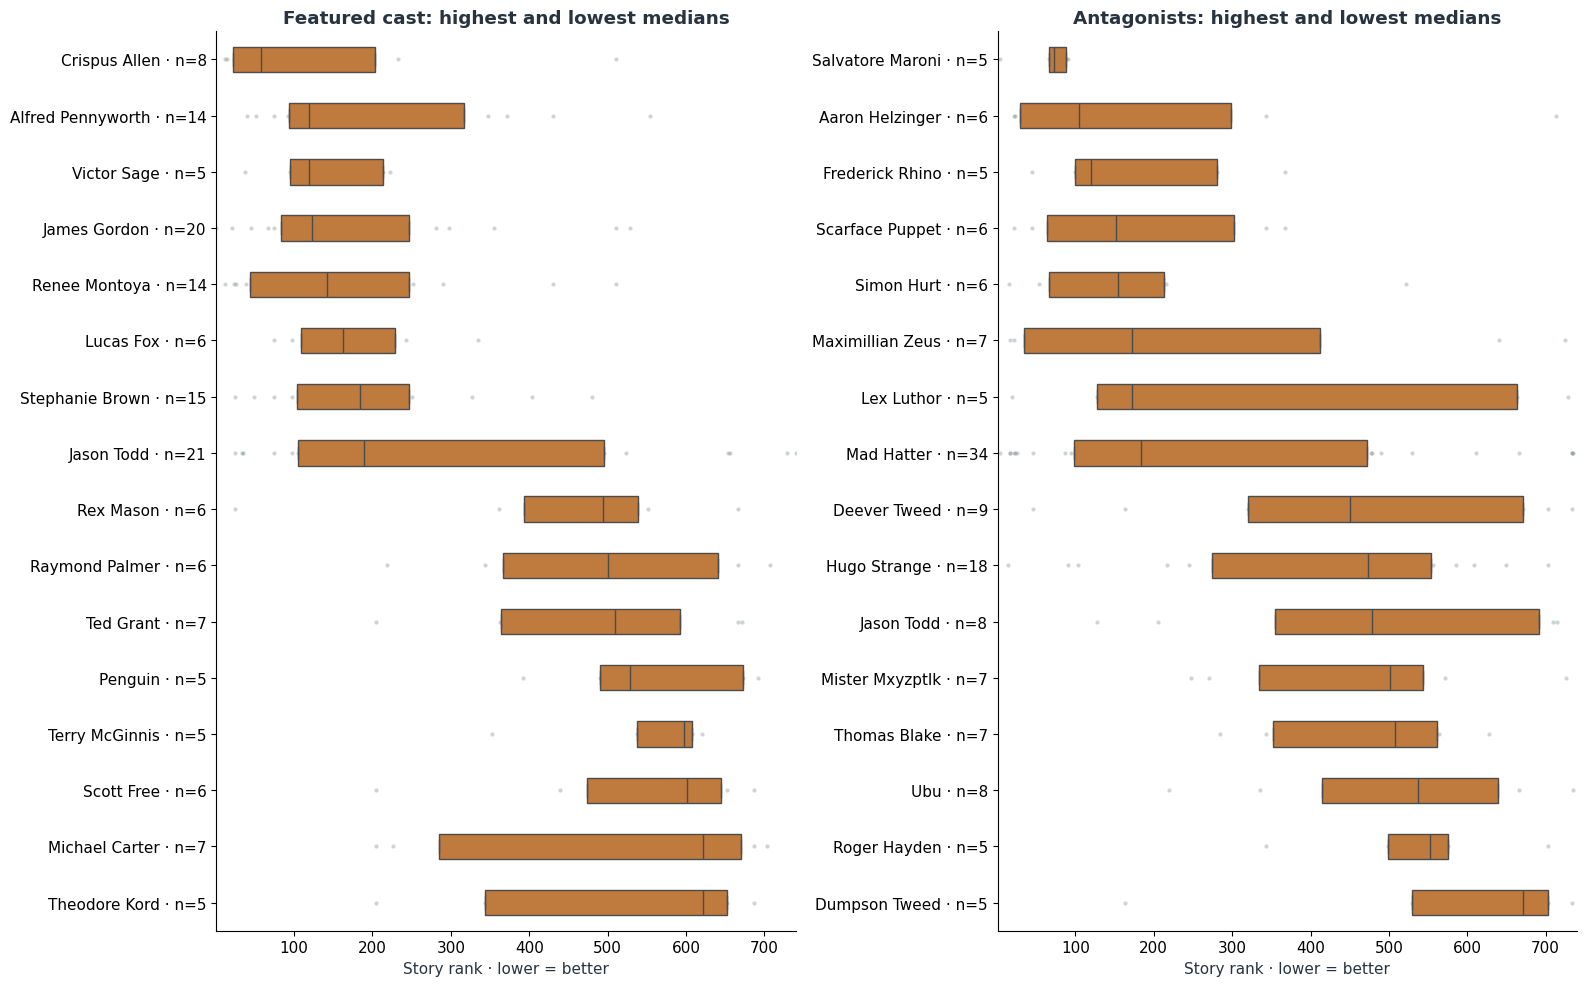

In [5]:
# Merge only the explicitly listed aliases; the source-name atlas above stays unchanged.
character_aliases = {'Edward Nashton': 'Riddler', 'Edward Nigma': 'Riddler', 'Edward Nygma': 'Riddler',
                     'Doctor Schivel': 'Mr. Freeze', 'Victor Fries': 'Mr. Freeze',
                     'Terrence McGinnis': 'Terry McGinnis'}
character_entries, character_profiles = {}, {}
for role, entries in [('Featured cast', featured), ('Antagonists', antagonists)]:
    merged = entries.assign(entity=entries.entity.replace(character_aliases)).drop_duplicates(['story_id','entity'])
    examples = merged.merge(s[['story_id','title']], on='story_id', validate='many_to_one').sort_values('rank')
    table = examples.groupby('entity').agg(n=('story_id','size'), median_rank=('rank','median'),
        best_rank=('rank','first'), best_story=('title','first'), worst_rank=('rank','last'), worst_story=('title','last'))
    table['display_name'] = [aliases.get(name, name) for name in table.index]
    character_entries[role] = merged
    character_profiles[role] = table.sort_values(['median_rank','n'], ascending=[True,False])
    assert not merged.duplicated(['story_id','entity']).any()
    character_profiles[role].to_csv(REPORT/('character_' + role.lower().replace(' ','_') + '_rankings.csv'))

groups = {'Gotham City Police Department', 'Batman Family', 'Justice League of America',
          'Birds of Prey', 'Justice League', 'Outsiders', 'Falcone Crime Family', 'Vampires',
          'Man-Bat Commandos', 'Gotham Organized Crime', 'Dinosaurs', 'Batman Villains',
          'Kobra Cult', 'Nazi Party', 'Secret Society of Super-Villains', 'Court of Owls',
          'League of Assassins', 'Zombies', 'False Face Society', 'Tweedledum and Tweedledee',
          'Regime', 'Demons'}
fig, axes = plt.subplots(1, 2, figsize=(16, 10), sharex=True)
for ax, (role, table), entries in zip(axes, character_profiles.items(), character_entries.values()):
    named = table[table.n.ge(5) & ~table.index.isin(groups)]
    extremes = pd.concat([named.head(8), named.tail(8)]).loc[lambda t: ~t.index.duplicated()]
    labels = extremes.apply(lambda r: f'{r.display_name} · n={int(r.n)}', axis=1)
    chart = entries[entries.entity.isin(extremes.index)].copy()
    chart['Character'] = chart.entity.map(labels)
    sns.stripplot(data=chart, x='rank', y='Character', order=labels.tolist(), ax=ax,
                  color=COLORS['grey'], alpha=.35, size=3, jitter=False, zorder=0)
    sns.boxplot(data=chart, x='rank', y='Character', order=labels.tolist(), ax=ax,
                color=COLORS['orange'], whis=0, showfliers=False, width=.45)
    ax.set(title=f'{role}: highest and lowest medians',
           xlabel='Story rank · lower = better', ylabel='', xlim=(1, N))
    examples = extremes[['display_name', 'n', 'median_rank', 'best_rank', 'best_story',
                         'worst_rank', 'worst_story']].rename(columns={
        'display_name':'Character', 'n':'Stories', 'median_rank':'Median rank',
        'best_rank':'Best rank', 'best_story':'Best-ranked story',
        'worst_rank':'Worst rank', 'worst_story':'Worst-ranked story'})
    display(HTML(f'<details><summary>{role}: best- and worst-ranked examples</summary>'
        '<p>All ranks: lower is better. Best and worst refer to this character’s stories.</p>'
        +examples.to_html(index=False, escape=True)+'</details>'))
fig.tight_layout()
save_figure(fig, REPORT, 'eda-character-highs-lows')


## Gorilla watch. Shark watch.

**The Joker’s Five-Way Revenge** (#11) features a shark tank. **Three Jokers** (#740) features a Jokerized shark. That is quite a range.

These are checked sightings from the available synopses and cast lists, including cameos and flashbacks. King Shark, robots, and splicers get separate labels. Tiger Shark and Great White Shark are human villains; they do not count. Missing stories are unconfirmed, not animal-free.

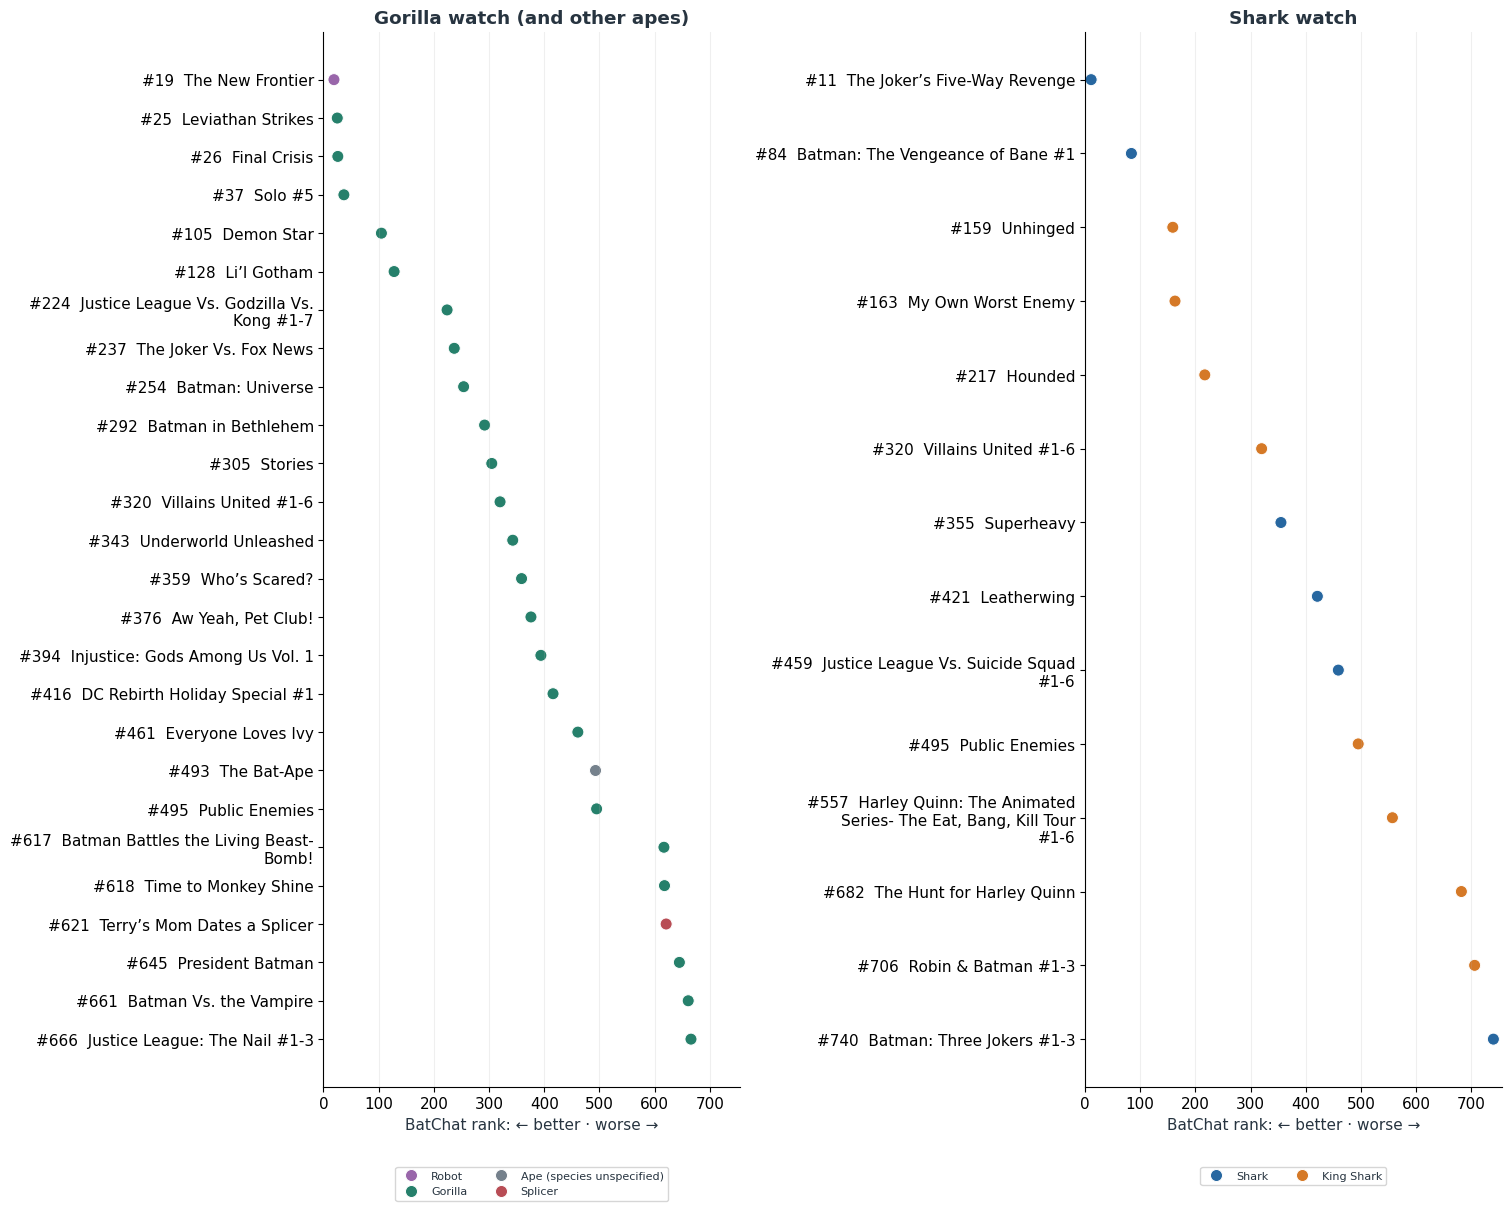

In [6]:
animal_watch = pd.read_csv(ROOT / 'data/external/animal_watch.csv')
assert animal_watch.story_id.isin(s.story_id).all()
assert animal_watch.source_url.str.startswith('https://dc.fandom.com/wiki/').all()
kinds = {'gorilla': 'Gorilla', 'ape': 'Ape (species unspecified)', 'shark': 'Shark',
         'shark_person': 'King Shark', 'robot': 'Robot', 'splicer': 'Splicer'}
watch = (animal_watch[animal_watch.classification.isin(kinds)]
         .drop_duplicates(['story_id', 'classification'])
         .merge(s[['story_id', 'title', 'rank']], on='story_id', validate='many_to_one')
         .sort_values('rank'))
watch['kind'] = watch.classification.map(kinds)
# One point per story and animal family; keep the more specific identification.
watch = watch.sort_values('classification', key=lambda x: x.map({'gorilla': 0, 'ape': 1}).fillna(2))
watch['family'] = watch.animal.replace({'ape': 'gorilla'})
watch = watch.drop_duplicates(['story_id', 'family']).sort_values('rank')
watch['label'] = watch['rank'].map('#{}'.format) + '  ' + watch.title.str.wrap(32)
watch.to_csv(REPORT / 'animal_watch_examples.csv', index=False)
fig, axes = plt.subplots(1, 2, figsize=(15, 12), layout='constrained')
palette = dict(zip(kinds.values(), ['#26806B', '#75818C', '#2767A0', '#D57927', '#9966AA', '#B84D55']))
for ax, animals, title in zip(axes, [{'gorilla', 'ape'}, {'shark'}], ['Gorilla watch (and other apes)', 'Shark watch']):
    part = watch[watch.animal.isin(animals)]
    sns.scatterplot(data=part, x='rank', y='label', hue='kind', palette=palette, s=75, ax=ax)
    ax.set(title=title, xlabel='BatChat rank: ← better · worse →', ylabel='', xlim=(0, len(s) + 15))
    ax.legend(title='', loc='upper center', bbox_to_anchor=(.5, -.07), fontsize=8, ncol=2)
    ax.grid(axis='x', alpha=.2)
save_figure(fig, REPORT, 'animal-watch')


In **Superheavy** (#355), Gordon’s robotic Batsuit uses two shark carcasses as clubs. That earns a note here, if nothing else.

The [animal audit](../data/external/animal_watch.csv) links every entry to its source and records the false matches. There are too few consistently documented sightings to estimate a gorilla or shark advantage.

### Wait—Mad Hatter?

Hatter's **34 stories** have a median rank of **183.5**. That's almost identical to Edward Nashton, one of Riddler's source names: **183 across 21 stories**. But what counts as a Hatter story?

| Story | Rank · 1 is best | Issues listing Hatter as an antagonist |
|---|---:|---:|
| *The Long Halloween* | 4 | 3 of 13 |
| *Dark Victory* | 16 | 2 of 14 |
| *Final Crisis* | 26 | 1 of 13 |
| *Unknowing* | 142 | 3 of 3 |
| *Madness* | 164 | 1 of 1 |
| *The Scoop of the Century* | 478 | 1 of 1 |
| *Mad* | 733 | 6 of 6 |

All 34 source records check out. His small role in *Final Crisis* counts as much as his central role in *Mad*.

Requiring him in **every issue** leaves 11 stories with a median of 183. So ensemble books aren't the whole explanation. *Unknowing*, *Madness*, and *Mad* also show how far Hatter-centered stories can spread. The [audit](../reports/hatter_credit_audit.csv) lists every source.

This ranks books containing Hatter. It doesn't rank Hatter himself.

### Is it the villain, or the era?

Perhaps those villains tend to appear in older books, or shorter ones. Let's compare stories from the **same decade and similar lengths**.

Orange dots show the average rank gap before grouping. Blue dots show it afterward. **Negative means stories with the antagonist rank better.** Both calculations use the same retained books.

<details><summary>How the comparison works</summary>

Length groups are 1, 2–4, and 5+ issues. Each decade/length group needs at least three stories with the antagonist and three without. We average the within-group gaps, weighted by the number with the antagonist.

Counts appear beside the names. Requiring comparable books drops some cases: the League of Assassins retains 12 of 26. Writers, other characters, and selection remain uncontrolled. No significance test is implied.

</details>

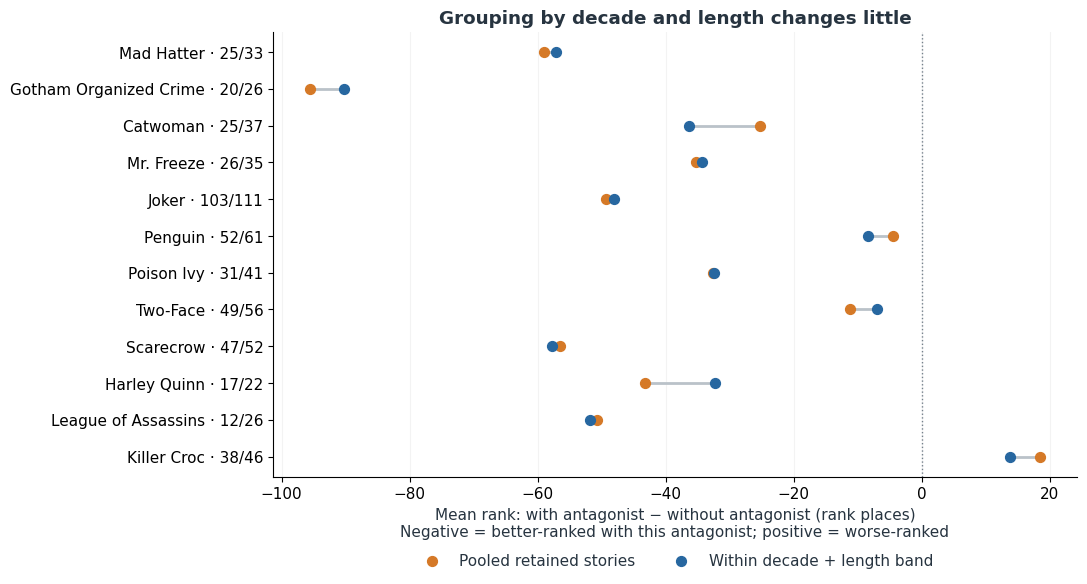

In [7]:
comparison=clean.dropna(subset=['decade']).copy()
comparison['length_band']=pd.cut(comparison.issue_count,[0,1,4,np.inf],labels=['1 issue','2–4 issues','5+ issues'])
comparison=comparison.dropna(subset=['length_band'])
comparisons=[]
for name in profile.index:
    present_ids=set(antagonists.loc[antagonists.entity.eq(name),'story_id'])
    sample=comparison.assign(present=comparison.story_id.isin(present_ids))
    retained=[];gaps=[];weights=[]
    for _,chunk in sample.groupby(['decade','length_band'],observed=True):
        present=chunk.loc[chunk.present,'rank'];absent=chunk.loc[~chunk.present,'rank']
        if len(present)>=3 and len(absent)>=3:
            retained.append(chunk);gaps.append(present.mean()-absent.mean());weights.append(len(present))
    if not retained:continue
    matched=pd.concat(retained)
    assert matched.story_id.is_unique and matched.present.sum()==sum(weights)
    within_gap=np.average(gaps,weights=weights)
    assert min(gaps)<=within_gap<=max(gaps)
    comparisons.append({'entity':name,'available_readings':int(sample.present.sum()),
        'retained_readings':int(matched.present.sum()),'comparison_readings':int((~matched.present).sum()),
        'strata':len(retained),'pooled_gap':matched.loc[matched.present,'rank'].mean()-matched.loc[~matched.present,'rank'].mean(),
        'within_decade_length_gap':within_gap})
character_check=pd.DataFrame(comparisons).set_index('entity').reindex(profile.index)
assert character_check.notna().all().all()
character_check.to_csv(REPORT/'antagonist_within_era_length.csv')
fig,ax=plt.subplots(figsize=(11,6))
for pos,(name,row) in enumerate(character_check.iterrows()):
    ax.plot([row.pooled_gap,row.within_decade_length_gap],[pos,pos],color='#BAC2C9',lw=2)
ax.scatter(character_check.pooled_gap,range(len(character_check)),color=COLORS['orange'],label='Pooled retained stories',s=50,zorder=3)
ax.scatter(character_check.within_decade_length_gap,range(len(character_check)),color=COLORS['blue'],label='Within decade + length band',s=50,zorder=3)
ax.axvline(0,color=COLORS['grey'],ls=':',lw=1)
ax.set(yticks=range(len(character_check)),yticklabels=[f'{aliases.get(name,name)} · {int(row.retained_readings)}/{int(row.available_readings)}' for name,row in character_check.iterrows()],
    xlabel='Mean rank: with antagonist − without antagonist (rank places)\nNegative = better-ranked with this antagonist; positive = worse-ranked',
    title='Grouping by decade and length changes little')
ax.invert_yaxis();ax.xaxis.grid(True,alpha=.15);ax.set_axisbelow(True)
ax.legend(loc='upper center',bbox_to_anchor=(.5,-.14),ncol=2,frameon=False)
fig.tight_layout();save_figure(fig,REPORT,'eda-antagonists-within-era')


Hatter and Scarecrow stories still average **57–58 places better** after grouping. Joker's gap is **48**. Penguin and Two-Face are close to zero, at about **8 and 7**.

Decade and length explain little of these particular comparisons. Specific writers or runs could still explain more.

## Which Batman series fare best?

*Gotham Central* follows Gotham's police. *Batman Adventures* brings the animated series to comics. *Legends of the Dark Knight* tells standalone Batman arcs. *Black and White* collects monochrome short stories.

Compare the twelve series represented by the most ranked stories. A story spanning several series appears in each. Volumes stay separate: *Batman* restarted at #1 more than once.

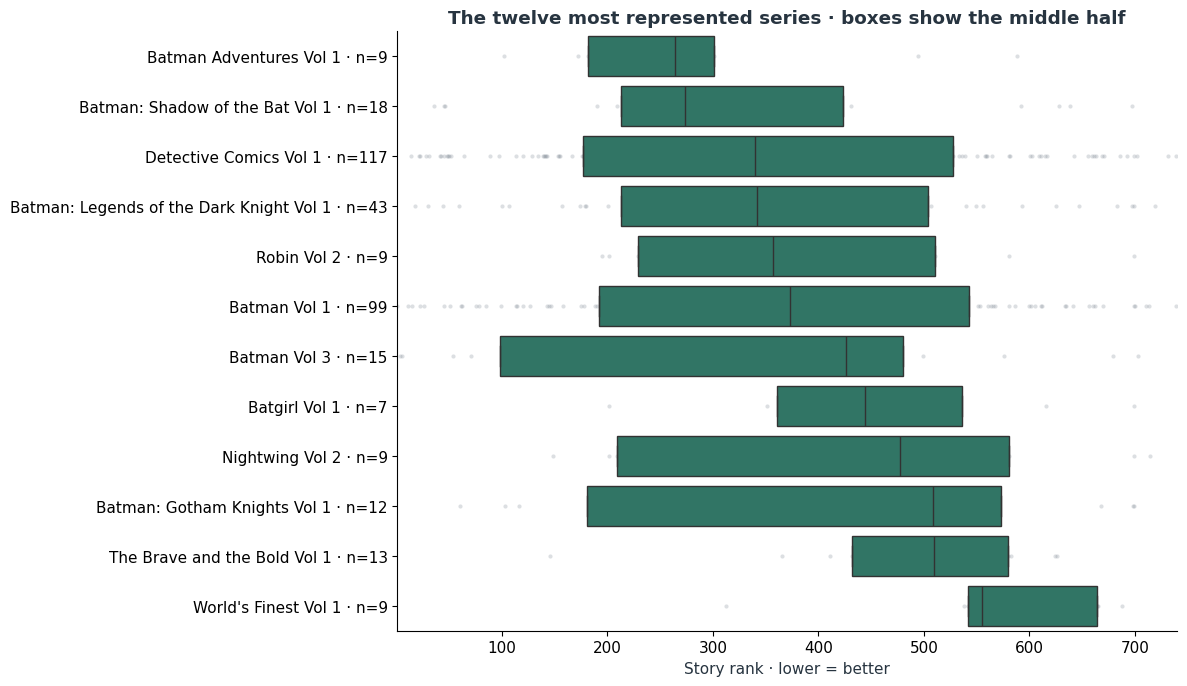

669 of 740 stories have a matched series title.


**Explicitly labeled original graphic novels:** 26 stories; median rank **352.5**. Unspecified formats are not a reliable comparison group.

Rank · 1 is best,Story
6,Batman/Dracula: Red Rain OGN
17,Arkham Asylum: A Serious House on Serious Earth OGN
23,Batman: Crimson Mist OGN
72,Catwoman: Selina’s Big Score OGN
94,Batman’s Mystery Casebook OGN
96,Batman & Robin & Howard OGN
101,Batman: War on Crime OGN
106,Batman : Birth of the Demon OGN
111,Batman: Bloodstorm OGN
124,Batman & Robin & Howard: Summer Breakdown OGN


,Stories,Median rank,Best rank,Best story,Worst rank,Worst story
Series,,,,,,
Batman Annual Vol 3,5,58.0,7,Some Of These Days,341,Batman V.3 Annual #1
Gotham Central Vol 1,6,73.5,12,Soft Targets,194,Nature
Catwoman Vol 3,5,132.0,27,Anodyne,699,War Games
Batman and Robin Vol 1,5,152.0,70,Batman and Robin Must Die!,216,Batman Vs. Robin
Batman: Legends of the Dark Knight Halloween Special Vol 1,3,164.0,144,Choices/Fears,299,Ghosts
JLA Vol 1,6,165.0,43,Tower of Babel,604,Bouncing Baby Boy
Batman '66 Vol 1,4,166.0,126,Batman ’66 V.1,223,Batman ’66 V.3
Batman Chronicles Vol 1,4,182.5,117,Oracle: Year One- Born of Hope,365,Batman Chronicles #11
Batman Eternal Vol 1,3,184.0,77,Batman: Eternal Part 1,243,Batman: Eternal V.2


In [8]:
series_links = issues[['story_id', 'wiki_title']].dropna().copy()
series_links['Series'] = series_links.wiki_title.str.extract(r'^(.* Vol \d+) \d+[A-Za-z]?$')[0]
series_links = series_links.dropna(subset=['Series']).drop_duplicates(['story_id', 'Series'])
series_links = series_links.merge(s[['story_id', 'rank', 'title']], on='story_id', validate='many_to_one')
series_rankings = (series_links.sort_values('rank').groupby('Series')
    .agg(stories=('story_id', 'nunique'), median_rank=('rank', 'median'),
         best_rank=('rank', 'first'), best_story=('title', 'first'),
         worst_rank=('rank', 'last'), worst_story=('title', 'last')))
series_rankings.to_csv(REPORT/'series_rankings.csv')
shown = series_rankings.nlargest(12, 'stories').sort_values('median_rank')
fig, ax = plt.subplots(figsize=(12, 7))
sns.stripplot(data=series_links[series_links.Series.isin(shown.index)], x='rank', y='Series',
              order=shown.index, color=COLORS['grey'], alpha=.25, size=3, jitter=False, ax=ax, zorder=0)
sns.boxplot(data=series_links[series_links.Series.isin(shown.index)], x='rank', y='Series',
            order=shown.index, color=COLORS['green'], whis=0, showfliers=False, ax=ax)
ax.set_yticks(range(len(shown)), [f'{name} · n={int(row.stories)}' for name,row in shown.iterrows()])
ax.set(xlabel='Story rank · lower = better', ylabel='', xlim=(1, N),
       title='The twelve most represented series · boxes show the middle half')
fig.tight_layout()
save_figure(fig, REPORT, 'eda-series')
print(f'{series_links.story_id.nunique()} of {N} stories have a matched series title.')

ogn = s[s.format_hint.eq('original_graphic_novel')].sort_values('rank')
display(Markdown(f'**Explicitly labeled original graphic novels:** {len(ogn)} stories; '
                 f'median rank **{ogn["rank"].median():.1f}**. Unspecified formats are not a reliable comparison group.'))
display(HTML('<details><summary>Original graphic novels: all 26 stories</summary>'
    +ogn[['rank','title']].rename(columns={'rank':'Rank · 1 is best','title':'Story'}).to_html(index=False, escape=True)+'</details>'))

series_table = series_rankings[series_rankings.stories.ge(3)].sort_values('median_rank')
display(HTML(f'<details><summary>All {len(series_table)} series with three or more ranked stories</summary>'
    '<p>Lower median rank is better. A cross-series story can appear in multiple rows.</p>'
    +series_table.rename(columns=lambda c: c.replace('_',' ').capitalize()).to_html(escape=True)
    +'</details>'))


### Elseworlds and graphic novels

**Elseworlds** puts familiar characters in alternate continuities. **32 stories** contain an issue explicitly labelled Elseworlds. **26** are called original graphic novels in the ranking list. These groups overlap.

The wiki also labels graphic novels, but that category can include collections. We show it separately. An absent label means unknown, so there is no “ordinary comics” control group here.

*Black and White* collects monochrome short stories. *Legends of the Dark Knight* often runs standalone arcs. Their series names are more useful than forcing both into an “anthology” category.

These wiki labels describe the containing issue, which can include other stories.

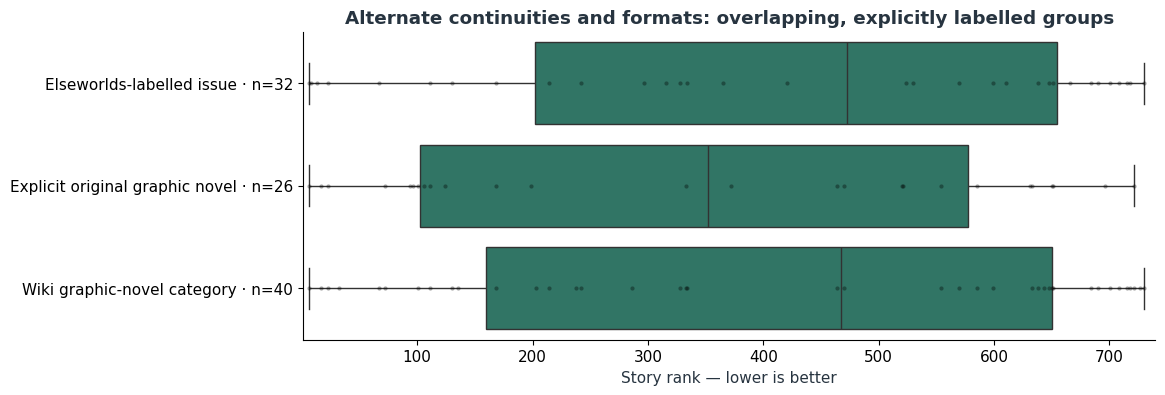

label,rank,title
Elseworlds-labelled issue,6,Batman/Dracula: Red Rain OGN
Elseworlds-labelled issue,8,The Dark Knight Returns
Elseworlds-labelled issue,13,Kingdom Come #1-4
Elseworlds-labelled issue,23,Batman: Crimson Mist OGN
Elseworlds-labelled issue,67,Batman: Gotham Noir
Elseworlds-labelled issue,111,Batman: Bloodstorm OGN
Elseworlds-labelled issue,130,Thrillkiller
Elseworlds-labelled issue,168,Batman: Nine Lives OGN
Elseworlds-labelled issue,214,Batman: Holy Terror
Elseworlds-labelled issue,242,Batman: Scar of the Bat


,stories,median_rank
event,,
Infinite Frontier,5,66.0
The New 52,4,67.0
Final Crisis,4,129.0
Batman R.I.P.,4,133.5
Return of Bruce Wayne,4,143.0
DC One Million,3,209.0
The Joker War,4,217.5
Batman: Reborn,7,219.0
Halloween,8,231.5


In [9]:
labels = pd.read_csv(ROOT / "data/external/story_labels.csv")
assert labels.story_id.is_unique and set(labels.story_id) == set(s.story_id)
label_books = s.merge(labels, on="story_id", validate="one_to_one")
format_groups = {
    "Elseworlds-labelled issue": label_books.elseworlds_issue_count.gt(0),
    "Explicit original graphic novel": label_books.format_hint.eq("original_graphic_novel"),
    "Wiki graphic-novel category": label_books.graphic_novel_issue_count.gt(0),
}
format_rows = pd.concat([
    label_books.loc[mask, ["story_id", "title", "rank"]].assign(label=name)
    for name, mask in format_groups.items()
], ignore_index=True)
format_counts = format_rows.groupby("label").size()
fig, ax = plt.subplots(figsize=(11, 4))
sns.boxplot(data=format_rows, x="rank", y="label", order=list(format_groups),
            color=COLORS["green"], showfliers=False, ax=ax)
sns.stripplot(data=format_rows, x="rank", y="label", order=list(format_groups),
              color="black", alpha=.35, jitter=False, size=3, ax=ax)
ax.set_yticks(range(len(format_groups)), [f"{name} · n={format_counts[name]}" for name in format_groups])
ax.set(xlabel="Story rank — lower is better", ylabel="", xlim=(1, N),
       title="Alternate continuities and formats: overlapping, explicitly labelled groups")
save_figure(fig, REPORT, "eda-story-labels")
format_rows.to_csv(REPORT / "story_label_examples.csv", index=False)
display(HTML("<details><summary>Labelled stories and their ranks</summary>" +
    format_rows.sort_values(["label", "rank"])[["label", "rank", "title"]].to_html(index=False) + "</details>"))

# A named event can be a holiday or relaunch, so it is not a crossover flag.
event_rows = label_books.loc[label_books.event_issue_count.gt(0), ["story_id", "rank", "event_names"]]
event_rows = event_rows.assign(event=event_rows.event_names.str.split("|")).explode("event")
event_summary = event_rows.groupby("event").agg(stories=("story_id", "nunique"), median_rank=("rank", "median"))
display(HTML("<details><summary>Named events with at least three stories (not necessarily crossovers)</summary>" +
    event_summary.query("stories >= 3").sort_values("median_rank").to_html() + "</details>"))


## Do younger writers fare worse?

Stories by writers under 30 have a median rank of **484**. That might suggest older writers fare better. Then we split the group:

- **1940s:** ten stories, median **543**.
- **1980s:** ten stories, median **141.5**.

Same age bracket, very different Batman comics. Compare ages across each row, then follow an age group down the decades. **Darker blue means better ranked.** Grey cells have fewer than five stories.

<details><summary>Calculating writer ages</summary>

The 512 included stories have complete issue lists and known ages for every writer. We calculate calendar-year age for the issues each person wrote, then use the median for co-written stories. These are approximate ages, not birthdays matched to publication dates.

</details>

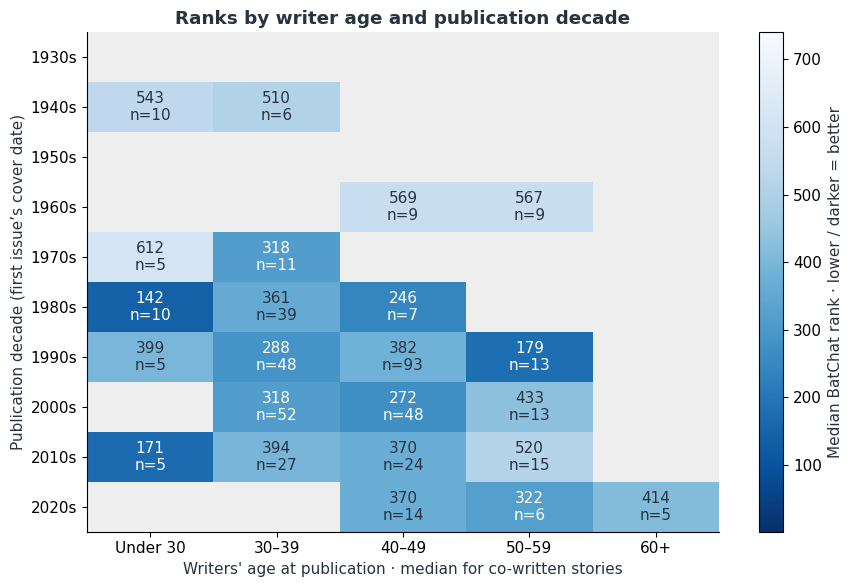

In [10]:
assert creators.creator_id.is_unique
assert not credits.duplicated(['story_id','creator_id','role','credit_scope']).any()
people=credits[credits.credit_scope.eq('selected_narrative')].merge(
    creators[['creator_id','name','gender','entity_type','eisner_personal_win_count_observed']],
    on='creator_id',validate='many_to_one')
people=people[~people.entity_type.isin(['organization','collective'])]
# Count unique creators within each role; repeat readings do not multiply this table.
unique_people=people.drop_duplicates(['role','creator_id'])
gender_by_role=pd.crosstab(unique_people.role,unique_people.gender.fillna('unreported'))

gender_by_role.to_csv(REPORT/'creator_gender_by_role.csv')
writer_age=credits[credits.credit_scope.eq('selected_narrative') & credits.role.eq('writers')].groupby('story_id').agg(
    writers=('creator_id','size'),known_ages=('age_at_publication_year_proxy','count'),
    age=('age_at_publication_year_proxy','median'))
writer_age=writer_age[writer_age.writers.eq(writer_age.known_ages)].merge(
    s[['story_id','rank','cover_year_start','metadata_complete','narrative_credit_issue_coverage']],
    on='story_id',validate='one_to_one')
writer_age=writer_age[writer_age.metadata_complete & writer_age.narrative_credit_issue_coverage.eq(1)]
writer_age['age_band']=pd.cut(writer_age.age,[-1,29,39,49,59,110],
                              labels=['Under 30','30–39','40–49','50–59','60+'])
writer_age['decade']=(writer_age.cover_year_start//10*10).astype(int)
profile=writer_age.groupby(['decade','age_band'],observed=True)['rank'].agg(n='size',median='median')
profile.to_csv(REPORT/'writer_age_by_decade.csv')

medians=profile['median'].unstack('age_band');counts=profile.n.unstack('age_band')
fig,ax=plt.subplots(figsize=(9,6))
values=medians.where(counts.ge(5))
image=ax.imshow(values.to_numpy(dtype=float),vmin=1,vmax=N,cmap='Blues_r',aspect='auto')
ax.set_facecolor('#EEEEEE')
ax.set_xticks(range(len(values.columns)),values.columns)
ax.set_yticks(range(len(values.index)),[f'{v}s' for v in values.index])
for row in range(len(values)):
    for col in range(len(values.columns)):
        if pd.notna(values.iloc[row,col]):
            ax.text(col,row,f'{values.iloc[row,col]:.0f}\nn={int(counts.iloc[row,col])}',
                    ha='center',va='center',color='white' if values.iloc[row,col]<350 else '#273440')
ax.set(xlabel="Writers' age at publication · median for co-written stories",ylabel='Publication decade (first issue’s cover date)',
       title='Ranks by writer age and publication decade')
fig.colorbar(image,ax=ax,label='Median BatChat rank · lower / darker = better')
fig.tight_layout();save_figure(fig,REPORT,'craft-writer-age-era')

Writer age and publication era are entangled here. The sparse cells show how little evidence we have for comparing ages within some decades.

## Same writer, different comic

*Red Rain* ranks **#6**. *Unseen* ranks **#716**. Both are by **Doug Moench and Kelley Jones**.

The chart compares four partnerships. Each dot is a story; each bar is a median. Even keeping both names fixed leaves plenty of room for a hit or a miss.

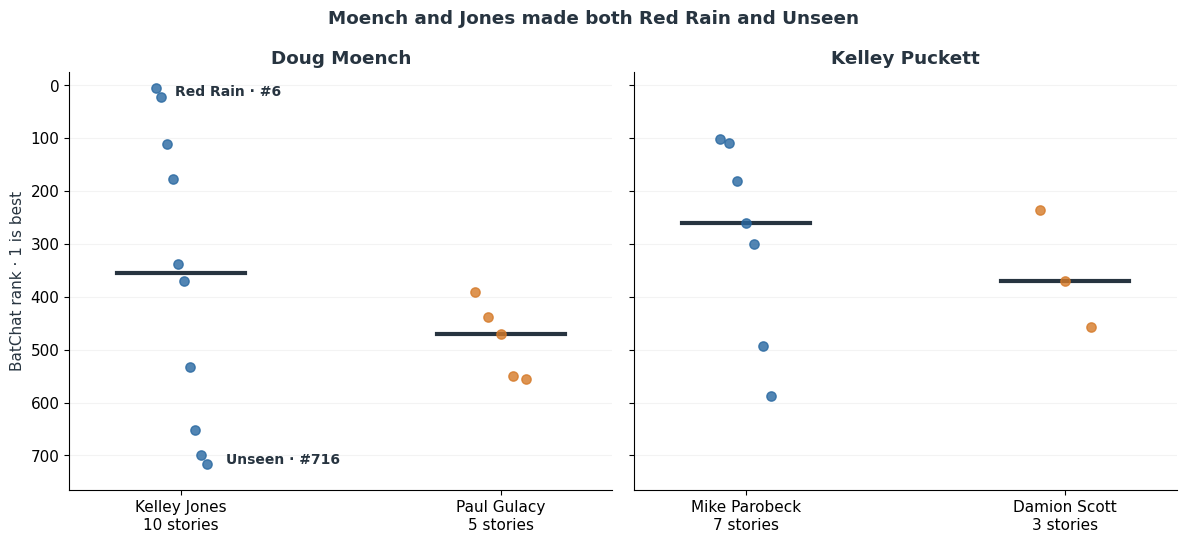

In [11]:
single=s[s.narrative_writers.map(split_set).map(len).eq(1)&s.narrative_pencilers.map(split_set).map(len).eq(1)
         &s.narrative_credit_issue_coverage.eq(1)].copy()
pairs=[('Doug Moench','Kelley Jones'),('Doug Moench','Paul Gulacy'),('Kelley Puckett','Mike Parobeck'),('Kelley Puckett','Damion Scott')]
rows=[]
for writer,artist in pairs:
    found=single[single.narrative_writers.eq(writer)&single.narrative_pencilers.eq(artist)]
    cast=entity_associations(found,'featured_entity_ids').entity.value_counts().head(3)
    rows.append({'writer':writer,'artist':artist,'n':len(found),'median_rank':found['rank'].median(),
                 'cover_years':f'{found.cover_year_start.min():.0f}–{found.cover_year_end.max():.0f}',
                 'frequent_featured_entities':'; '.join(cast.index)})
partnerships=pd.DataFrame(rows)
partnerships.to_csv(REPORT/'creative_partnerships.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(12,5.5),sharey=True)
for ax,writer in zip(axes,['Doug Moench','Kelley Puckett']):
    artist_labels=[]
    for pos,(_,artist) in enumerate([p for p in pairs if p[0]==writer]):
        found=single.loc[single.narrative_writers.eq(writer)&single.narrative_pencilers.eq(artist)].sort_values('rank')
        values=found['rank'].to_numpy()
        x=pos+np.linspace(-.08,.08,len(values))
        ax.scatter(x,values,s=45,alpha=.8,color=[COLORS['blue'],COLORS['orange']][pos],zorder=3)
        if len(values):ax.plot([pos-.2,pos+.2],[np.median(values)]*2,color='#273440',lw=3)
        artist_labels.append(f'{artist}\n{len(values)} stories')
        if artist=='Kelley Jones':
            for k,label,offset in [(0,'Red Rain · #6',(14,-2)),(-1,'Unseen · #716',(14,3))]:
                ax.annotate(label,(x[k],values[k]),xytext=offset,textcoords='offset points',
                            fontsize=10,va='center',fontweight='bold')
    ax.set(xticks=[0,1],xticklabels=artist_labels,title=writer,xlim=(-.35,1.35))
    ax.yaxis.grid(True,alpha=.15);ax.set_axisbelow(True)
axes[0].set(ylabel='BatChat rank · 1 is best',ylim=(N+25,-25))
fig.suptitle('Moench and Jones made both Red Rain and Unseen',fontweight='bold')
fig.tight_layout();save_figure(fig,REPORT,'craft-partnerships')

Kelley Puckett's books with Mike Parobeck have a median rank of **261 across seven stories**. With Damion Scott, it's **371 across three**.

But Parobeck's books belong to *Batman: The Animated Series*' world. Scott's include Cassandra Cain's early *Batgirl* stories and her introduction in *No Man's Land*. The artist, protagonist, and kind of comic change together. Calling the difference “artist quality” would miss that. [DC on Batman Adventures](https://www.dc.com/graphic-novels/batman-adventures-1992/batman-adventures-vol-2) · [DC on Scott and Cassandra Cain](https://www.dc.com/blog/2023/02/23/power-on-page-six-dc-comics-by-black-creators)

### Does keeping one team help an arc?

An artist change halfway through a story can be jarring. Arcs with the same writers and pencilers throughout have a median rank of **316.5**, versus **340** for changing teams.

Longer arcs have more opportunities to change artists. The difference depends on length: stable teams rank about **30 places better at 3–4 issues**, **5 better at 5–6**, and **6 worse at 7+**.

The dots tell the bigger story: both groups span much of the ranking.

<details><summary>Which arcs qualify?</summary>

At least three issues, complete issue lists, one selected story per issue, and known writers and pencilers throughout. “Stable” means the same set of those people in every issue.

</details>

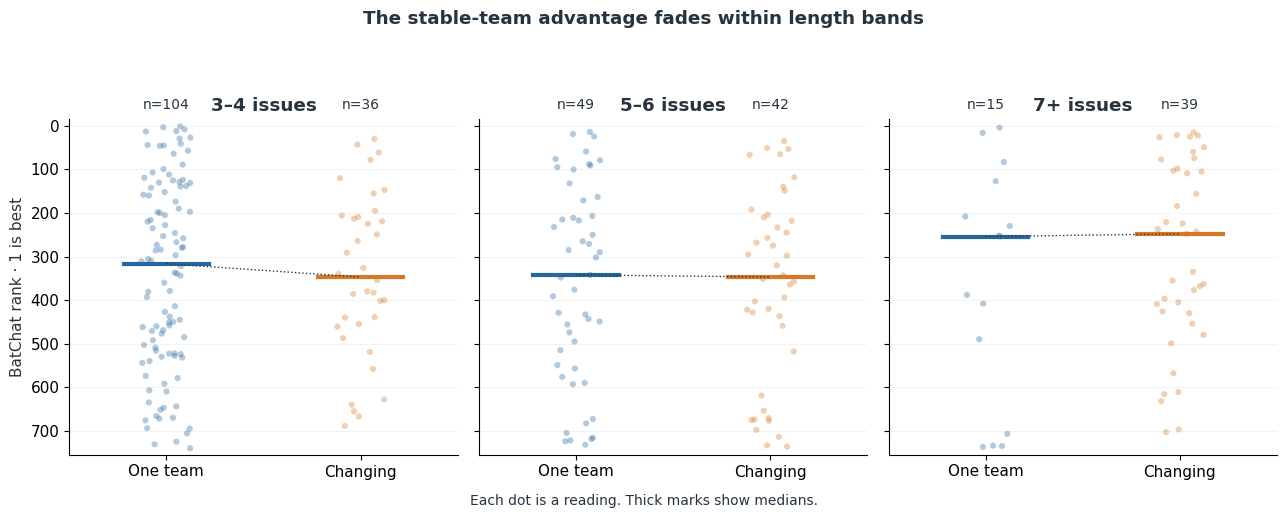

In [12]:
multi_narrative_entries=set(issues.loc[issues.selected_substory_indexes.fillna('').str.contains('|',regex=False),'story_id'])
teams=s[s.issue_count.ge(3) & ~s.story_id.isin(multi_narrative_entries) & s.metadata_complete & s.narrative_credit_issue_coverage.eq(1)].copy()
teams['stable_team']=teams.narrative_dominant_team_share.eq(1)
teams['length_band']=pd.cut(teams.issue_count,[2,4,6,np.inf],labels=['3–4 issues','5–6 issues','7+ issues'])
team_table=teams.groupby(['length_band','stable_team'],observed=True)['rank'].agg(n='size',median_rank='median')
# Keep the full counts and medians in the exported table.
team_table.to_csv(REPORT/'team_stability_by_length.csv')
fig,axes=plt.subplots(1,3,figsize=(13,4.5),sharey=True)
for ax,band in zip(axes,['3–4 issues','5–6 issues','7+ issues']):
    medians=[]
    for pos,(same,color,label) in enumerate([(True,COLORS['blue'],'One team'),(False,COLORS['orange'],'Changing')]):
        values=teams.loc[teams.length_band.eq(band)&teams.stable_team.eq(same),'rank'].sort_values().to_numpy()
        medians.append(np.median(values))
        ax.scatter(pos+np.random.default_rng(42).uniform(-.13,.13,len(values)),values,
                   s=20,alpha=.35,color=color,edgecolors='none')
        ax.plot([pos-.22,pos+.22],[np.median(values)]*2,color=color,lw=3)
        ax.text(pos,1.03,f'n={len(values)}',transform=ax.get_xaxis_transform(),ha='center',fontsize=10)
    ax.plot([0,1],medians,color='#273440',lw=1,ls=':')
    ax.set(xticks=[0,1],xticklabels=['One team','Changing'],xlim=(-.5,1.5),title=band)
    ax.title.set_position((.5,1.12));ax.yaxis.grid(True,alpha=.15);ax.set_axisbelow(True)
axes[0].set(ylim=(N+15,-15),ylabel='BatChat rank · 1 is best')
fig.suptitle('The stable-team advantage fades within length bands',y=1.08,fontweight='bold')
fig.text(.5,-.02,'Each dot is a reading. Thick marks show medians.',ha='center',fontsize=10)
fig.tight_layout();save_figure(fig,REPORT,'craft-team-continuity')


### The names that recur across runs

John Costanza and Todd Klein lead the lettering counts. Adrienne Roy leads color. These names connect books that fans tend to discuss by writer or penciler.

Across the same **589 stories**, the five most frequent letterers account for **34.6%** of lettering assignments. The equivalent shares are **18.3%** for writers and **9.5%** for pencilers.

<details><summary>Counting shared assignments</summary>

Every story contributes one unit per role, divided equally among its contributors. Two writers get half each. All 589 stories have all six roles recorded. Studios remain included. These shares describe this list, not industry employment or working hours.

</details>

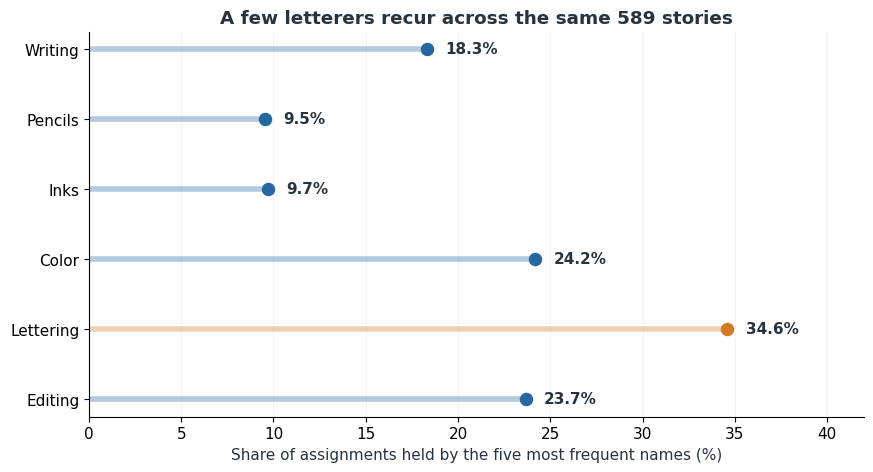

,Name,Stories
Role,,
Editing,Dennis O'Neil,113
Color,Adrienne Roy,66
Lettering,John Costanza,69
Lettering,Todd Klein,67
Writing,Chuck Dixon,33
Writing,Alan Grant,30
Color,Dave Stewart,27
Editing,Scott Peterson,43
Inks,Rick Burchett,17


In [13]:
roles=['writers','pencilers','inkers','colorists','letterers','editors']
complete_ids=s.loc[s.metadata_complete & s.substory_attribution_coverage.eq(1)
                  & s.narrative_credit_issue_coverage.eq(1),'story_id']
role_links=credits[credits.credit_scope.eq('selected_narrative') & credits.story_id.isin(complete_ids)].copy()
common=role_links.groupby('story_id').role.nunique()
role_links=role_links[role_links.story_id.isin(common[common.eq(len(roles))].index)]
assert set(role_links.role)==set(roles)
assert not role_links.duplicated(['story_id','role','creator_id']).any()
role_links['credit_share']=1/role_links.groupby(['story_id','role']).creator_id.transform('size')
assert np.allclose(role_links.groupby(['story_id','role']).credit_share.sum(),1)
credit_counts=role_links.groupby(['role','creator_id']).agg(
    readings=('story_id','nunique'),allocated_credits=('credit_share','sum')).reset_index()
credit_counts=credit_counts.merge(creators[['creator_id','name','entity_type']],on='creator_id',validate='many_to_one')
common_n=role_links.story_id.nunique()
assert role_links.groupby('role').story_id.nunique().eq(common_n).all()
credit_counts['share']=credit_counts.allocated_credits/common_n
leaders=credit_counts.sort_values('share',ascending=False).groupby('role').head(5)
concentration=leaders.groupby('role').share.sum().reindex(roles).rename('top_five_share').to_frame()
concentration['distinct_credit_entities']=credit_counts.groupby('role').size()
concentration['readings']=common_n
concentration.to_csv(REPORT/'credit_concentration_by_role.csv')
credit_counts.to_csv(REPORT/'creator_credit_frequency.csv',index=False)
fig,ax=plt.subplots(figsize=(10,5))
labels={'writers':'Writing','pencilers':'Pencils','inkers':'Inks','colorists':'Color','letterers':'Lettering','editors':'Editing'}
for pos,(role,row) in enumerate(concentration.iterrows()):
    value=row.top_five_share*100
    color=COLORS['orange'] if role=='letterers' else COLORS['blue']
    ax.hlines(pos,0,value,color=color,lw=4,alpha=.35)
    ax.scatter(value,pos,s=75,color=color,zorder=3)
    ax.text(value+1,pos,f'{value:.1f}%',va='center',fontweight='bold')
ax.set(yticks=range(len(roles)),yticklabels=[labels[r] for r in roles],xlim=(0,42),
       xlabel='Share of assignments held by the five most frequent names (%)',
       title=f'A few letterers recur across the same {common_n} stories')
ax.invert_yaxis();ax.xaxis.grid(True,alpha=.15);ax.set_axisbelow(True)
save_figure(fig,REPORT,'craft-credit-concentration')
top_names=credit_counts.sort_values('share',ascending=False).groupby('role').head(2)
display(top_names.assign(Role=top_names.role.map(labels)).rename(columns={
    'name':'Name','readings':'Stories'})[['Role','Name','Stories']].set_index('Role'))

## Same length, different ways to tell a story

*Undone* uses **20 silent pages**. *The Clown at Midnight* uses **22 pages of illustrated prose**. They rank **47th and 85th**. Similar lengths, different reading experiences. [DC on the silent issue](https://www.dc.com/blog/2013/09/05/5-2-reasons-dc-comics-the-new-52-anniversary-edition)

A wiki summary can describe a silent image at length or compress pages of dialogue into a sentence. Its word count doesn't measure how wordy the comic is.

### A plot summary can't show you this

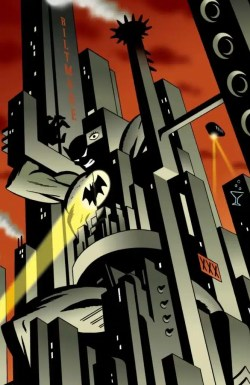

Batman almost disappears into the angular black shapes of Gotham. The orange sky separates the towers. A yellow beam draws the eye diagonally across the scene.

“Batman above Gotham” captures the subject. It loses the composition.

Color also depends on the edition. Richmond Lewis colored *Year One* twice for different presentations. Studying that difference would require knowing which version the hosts read. [DC on Richmond Lewis](https://www.dc.com/blog/2024/03/29/the-woman-whose-colors-brought-batman-year-one-to-life-twice)

*Darwyn Cooke artwork for Ego, © DC. Small image reproduced by [ComicsXF](https://comicsxf.com/batchat-rankings/); [image source](https://i0.wp.com/www.comicsxf.com/wp-content/uploads/2022/06/batman-ego-666x1024.webp?resize=640%2C984). Included for the visual commentary above.*

In [14]:
texts=pd.read_csv(ROOT/'data/processed/story_texts.csv')
assert not texts.duplicated(['story_id','requested_title','substory_index']).any()
text_profile=texts.groupby('story_id').agg(
    narrative_rows=('text_status','size'),available_synopses=('text_status',lambda v:v.eq('available').sum()),
    available_words=('synopsis_word_count','sum'))
text_profile=text_profile.merge(s[['story_id','title','issue_list_complete']],on='story_id',validate='one_to_one')
text_profile['all_selected_texts_available']=(text_profile.available_synopses.eq(text_profile.narrative_rows)
                                             & text_profile.issue_list_complete)
text_profile.to_csv(REPORT/'synopsis_coverage.csv',index=False)

## What do the plots sound like?

We have **1,711 uncapped summaries**, totaling **703,219 words**. **587 stories** have some text; **481** have every selected summary and a complete issue list.

Before looking at the words, check which books they represent. The 1980s have complete text for **59 of 69** stories. The 2020s have **8 of 69**. A text analysis will disproportionately describe older books.

Green means complete, orange partial, grey no usable text. The numbers count stories. Seven stories have no known decade.

The [prediction notebook](1.0-batchat-rankings.ipynb#does-knowing-the-plot-help) tests whether the words improve rank predictions after accounting for text availability and length.

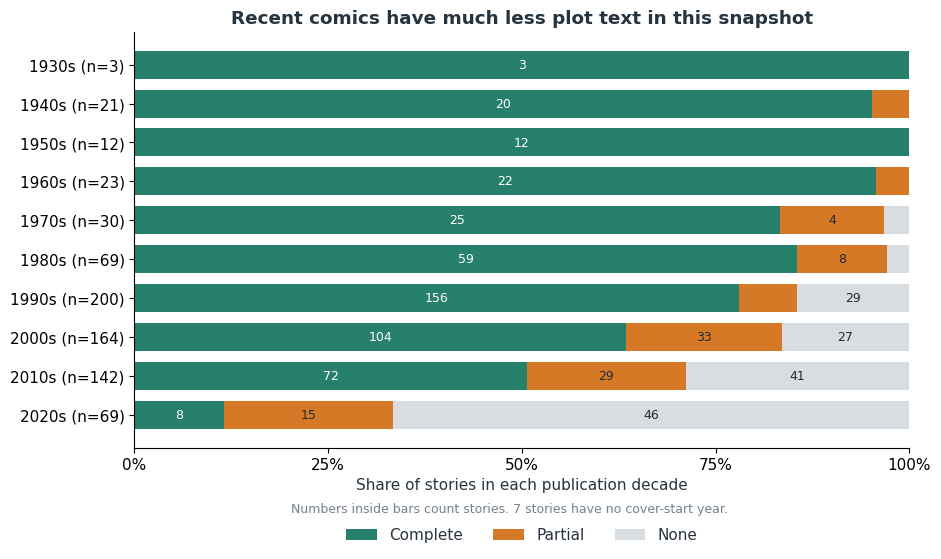

Unknown cover-start decade: 7 stories; 0 have some plot text.


In [15]:
text_era=s[['story_id','cover_year_start']].merge(
    text_profile[['story_id','available_synopses','all_selected_texts_available']],
    on='story_id',how='left',validate='one_to_one')
assert len(text_era)==N and text_era.available_synopses.notna().all()
text_era['decade']=(text_era.cover_year_start//10*10).astype('Int64')
text_era['coverage']=np.select(
    [text_era.all_selected_texts_available,text_era.available_synopses.gt(0)],
    ['Complete','Partial'],default='None')
coverage_order=['Complete','Partial','None']
text_by_era=pd.crosstab(text_era.decade,text_era.coverage).reindex(columns=coverage_order,fill_value=0)
text_by_era['n']=text_by_era.sum(axis=1)
unknown_era=text_era.decade.isna().sum()
assert text_by_era['n'].sum()+unknown_era==N
text_by_era.to_csv(REPORT/'synopsis_coverage_by_decade.csv')
fig,ax=plt.subplots(figsize=(10,5.4))
left=np.zeros(len(text_by_era))
for status,color in zip(coverage_order,[COLORS['green'],COLORS['orange'],'#D8DDE1']):
    width=100*text_by_era[status]/text_by_era['n']
    ax.barh(np.arange(len(text_by_era)),width,left=left,color=color,label=status,height=.72)
    for pos,(share,count) in enumerate(zip(width,text_by_era[status])):
        if share>=9:
            ax.text(left[pos]+share/2,pos,str(count),ha='center',va='center',
                    color='white' if status=='Complete' else '#202B35',fontsize=9)
    left+=width.to_numpy()
ax.set(yticks=np.arange(len(text_by_era)),
       yticklabels=[f'{decade}s (n={int(row.n)})' for decade,row in text_by_era.iterrows()],
       xticks=[0,25,50,75,100],xticklabels=['0%','25%','50%','75%','100%'],xlim=(0,100),
       xlabel='Share of stories in each publication decade',
       title='Recent comics have much less plot text in this snapshot')
ax.invert_yaxis()
ax.legend(loc='upper center',bbox_to_anchor=(.5,-.16),ncol=3,frameon=False)
fig.text(.5,-.01,f'Numbers inside bars count stories. {unknown_era} stories have no cover-start year.',
         ha='center',fontsize=9,color=COLORS['grey'])
save_figure(fig,REPORT,'craft-synopsis-coverage')

print(f'Unknown cover-start decade: {unknown_era} stories; '
      f'{text_era.loc[text_era.decade.isna(),"available_synopses"].gt(0).sum()} have some plot text.')

### Vampires, nightmares, and other plot ingredients

Vampire mentions turn up in **nine fully summarized stories**, from *Red Rain* (#6) to *Superman and Batman vs. Vampires and Werewolves* (#732). A premise leaves plenty of room for execution.

These are word searches, not hand-labelled themes. A dream can be a passing remark. Each dot is one story, counted once per row. We use the 481 stories with complete summaries; longer summaries have more chances to match.

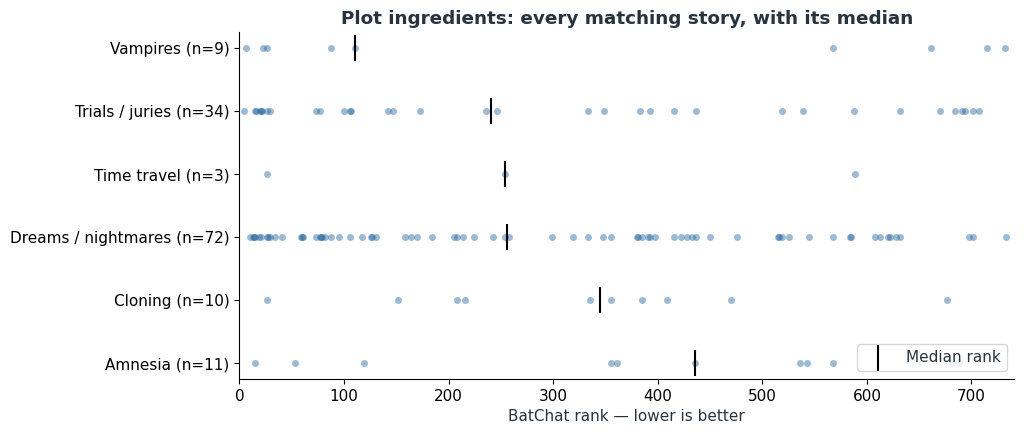

,Stories,Median rank (lower = better),Highest-ranked story,Lowest-ranked story
topic,,,,
Vampires,9,111.0,Batman/Dracula: Red Rain OGN,Superman and Batman Vs. Vampires and Werewolves
Trials / juries,34,241.0,The Long Halloween,Identity Crisis
Time travel,3,254.0,Final Crisis,DCU Infinite Holiday Special #1
Dreams / nightmares,72,256.0,Batman: Black and White Vol.1,Mad
Cloning,10,345.0,Final Crisis,The Amazo Virus
Amnesia,11,436.0,Batman: R.I.P.,Superman’s Secret Kingdom


In [16]:
from scripts.analysis import plot_documents

plot_terms = {
    "Vampires": r"\bvampir\w*",
    "Dreams / nightmares": r"\b(?:dreams?|nightmares?)\b",
    "Amnesia": r"\b(?:amnesia|amnesiac)\b",
    "Time travel": r"\btime[- ]trav\w*",
    "Trials / juries": r"\b(?:trial|jury|courtroom)\b",
    "Cloning": r"\bclon(?:e[sd]?|ing)\b",
}
plot_books = plot_documents(s, texts).merge(
    s[["story_id", "title", "rank"]], on="story_id", validate="one_to_one"
).query("plot_complete == 1")
term_matches = pd.concat([
    plot_books.loc[plot_books.plot_text.str.contains(pattern, case=False, regex=True),
                   ["story_id", "title", "rank"]].assign(topic=topic)
    for topic, pattern in plot_terms.items()
], ignore_index=True)
assert not term_matches.duplicated(["story_id", "topic"]).any()
term_summary = term_matches.groupby("topic").agg(
    stories=("story_id", "size"), median_rank=("rank", "median")
).sort_values("median_rank")
order = term_summary.index.tolist()
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.stripplot(data=term_matches, x="rank", y="topic", order=order,
              jitter=False, alpha=.45, color=COLORS["blue"], ax=ax)
ax.scatter(term_summary.median_rank, range(len(order)), marker="|", s=350,
           color="black", label="Median rank", zorder=4)
ax.set_yticks(range(len(order)), [f"{k} (n={term_summary.loc[k, 'stories']})" for k in order])
ax.set(xlim=(0, N + 1), xlabel="BatChat rank — lower is better", ylabel="",
       title="Plot ingredients: every matching story, with its median")
ax.legend(loc="lower right")
save_figure(fig, REPORT, "plot-ingredients")
plt.show()
examples = term_matches.sort_values("rank").groupby("topic").agg(
    highest_ranked=("title", "first"), lowest_ranked=("title", "last")
)
display(term_summary.join(examples).rename(columns={
    "stories": "Stories", "median_rank": "Median rank (lower = better)",
    "highest_ranked": "Highest-ranked story", "lowest_ranked": "Lowest-ranked story"
}))
term_matches.to_csv(REPORT / "plot_ingredient_matches.csv", index=False)


### Gotham without “Batman”

The bat collects words from the **481 completely summarized stories**. Larger words occur in more stories. Repeating a word within one story adds nothing.

We remove common English words and a fixed list of character and setting names. Word forms stay separate. **Rankings play no part in these clouds.**

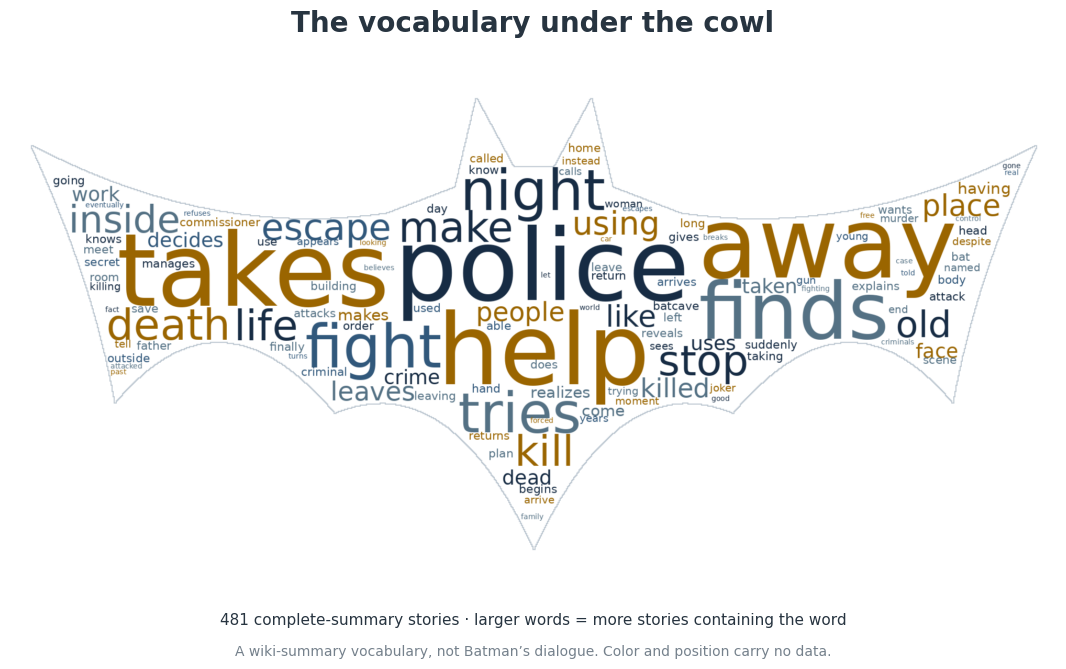

In [17]:
from matplotlib.font_manager import findfont
from matplotlib.path import Path as ShapePath
from matplotlib.colors import ListedColormap
from PIL import Image, ImageDraw, ImageFont
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS
from wordcloud import WordCloud
from scripts.analysis import plot_documents

plot_docs = plot_documents(s, texts)
cloud_docs = plot_docs.loc[plot_docs.plot_complete.eq(1)].reset_index(drop=True)
# Keep names from answering the character comparison before it starts.
extra_stopwords = set("""batman bruce wayne gotham city robin dick grayson tim drake
    jason todd alfred gordon riddler edward nashton nigma nygma penguin oswald cobblepot
    tells says asks comes goes gets just later soon new man men time way back
    couldn didn doesn isn wasn wouldn don ve ll aren weren hasn hadn haven shouldn needn mustn mightn won shan""".split())
vectorizer = CountVectorizer(binary=True, min_df=3,
    stop_words=sorted(ENGLISH_STOP_WORDS | extra_stopwords),
    token_pattern=r'(?u)\b[a-zA-Z]{3,}\b')
word_presence = vectorizer.fit_transform(cloud_docs.plot_text)
terms = vectorizer.get_feature_names_out()
word_counts = word_presence.sum(axis=0).A1
assert cloud_docs.story_id.is_unique and set(word_presence.data) == {1}
assert word_counts.max() <= len(cloud_docs)

# Original geometric silhouettes; no downloaded logo or comic art.
bat_outline = ShapePath(
    [(20,90),(190,180),(360,155),(425,130),(445,45),(480,110),(520,110),
     (555,45),(575,130),(640,155),(810,180),(980,90),(920,220),(900,335),
     (800,215),(690,345),(580,300),(500,475),(420,300),(310,345),
     (200,215),(100,335),(80,220),(20,90),(20,90)],
    [1,3,3,2,2,2,2,2,2,2,3,3,3,3,3,3,3,3,3,3,3,3,3,3,79])
yy, xx = np.mgrid[:520, :1000]
bat_mask = np.where(bat_outline.contains_points(
    np.column_stack([xx.ravel(), yy.ravel()])).reshape(xx.shape), 0, 255).astype('uint8')
font_path = findfont('DejaVu Sans')
question = Image.new('L', (600,600), 255)
draw = ImageDraw.Draw(question)
font = ImageFont.truetype(findfont('DejaVu Sans:weight=bold'), 780)
x0,y0,x1,y1 = draw.textbbox((0,0), '?', font=font)
draw.text(((600-x1+x0)/2-x0, (600-y1+y0)/2-y0), '?', font=font, fill=0)
umbrella = Image.new('L', (600,600), 255)
draw = ImageDraw.Draw(umbrella)
draw.pieslice((20,60,580,620), 180, 360, fill=0)
draw.rectangle((280,300,325,455), fill=0)
draw.arc((185,385,325,525), 0, 180, fill=0, width=45)
masks = {'Bat':bat_mask, 'Riddler':np.where(np.array(question) < 128, 0, 255).astype('uint8'), 'Penguin':np.array(umbrella)}
assert all(set(np.unique(mask)) == {0,255} and (mask == 0).mean() > .1
           for mask in masks.values())

common = pd.DataFrame({'term':terms, 'readings_with_word':word_counts})
common['readings_total'] = len(cloud_docs)
common['reading_share_pct'] = 100*common.readings_with_word/len(cloud_docs)
common = common.sort_values(['readings_with_word','term'], ascending=[False,True]).head(120)
common.to_csv(REPORT/'plot_cloud_common_words.csv', index=False)
bat_cloud = WordCloud(mask=bat_mask, background_color='white', font_path=font_path,
    random_state=42, max_words=120, scale=2, prefer_horizontal=1,
    colormap=ListedColormap(['#172C44','#31587B','#9A6500','#547184']),
    contour_width=1, contour_color='#BBC6D0').generate_from_frequencies(
        common.set_index('term').readings_with_word.to_dict())
fig,ax = plt.subplots(figsize=(12,6.8))
ax.imshow(bat_cloud, interpolation='bilinear')
ax.axis('off')
ax.set_title('The vocabulary under the cowl', fontsize=20, pad=14)
fig.text(.5,.10, f'{len(cloud_docs)} complete-summary stories · larger words = more stories containing the word',
    ha='center', fontsize=11)
fig.text(.5,.055, 'A wiki-summary vocabulary, not Batman’s dialogue. Color and position carry no data.',
    ha='center', fontsize=10, color=COLORS['grey'])
fig.tight_layout(rect=(0,.12,1,1))
save_figure(fig, REPORT, 'eda-bat-word-cloud')


### Riddler's puzzles, Penguin's business

“Takes,” “away,” and “finds” are the language of recounting a plot. “Police,” “death,” and “escape” feel more like Gotham. Which words distinguish particular villains?

Below, larger words are **more common relative to the other stories**. A word must appear in at least five stories featuring that villain as an antagonist.

<details><summary>How the comparison works</summary>

We merge Riddler's Nashton, Nigma, and Nygma aliases, and Penguin's named and generic entries. Ensemble appearances count. Both groups require complete plot and cast records.

Word size starts from the log2 ratio of story proportions, with one added to the word counts and two to the group sizes. A score of 1 means twice the smoothed prevalence. Only positive scores appear. Each cloud scales independently; color and position carry no information. The code shows the exclusions and original geometric masks. [WordCloud documentation](https://amueller.github.io/word_cloud/generated/wordcloud.WordCloud.html)

</details>

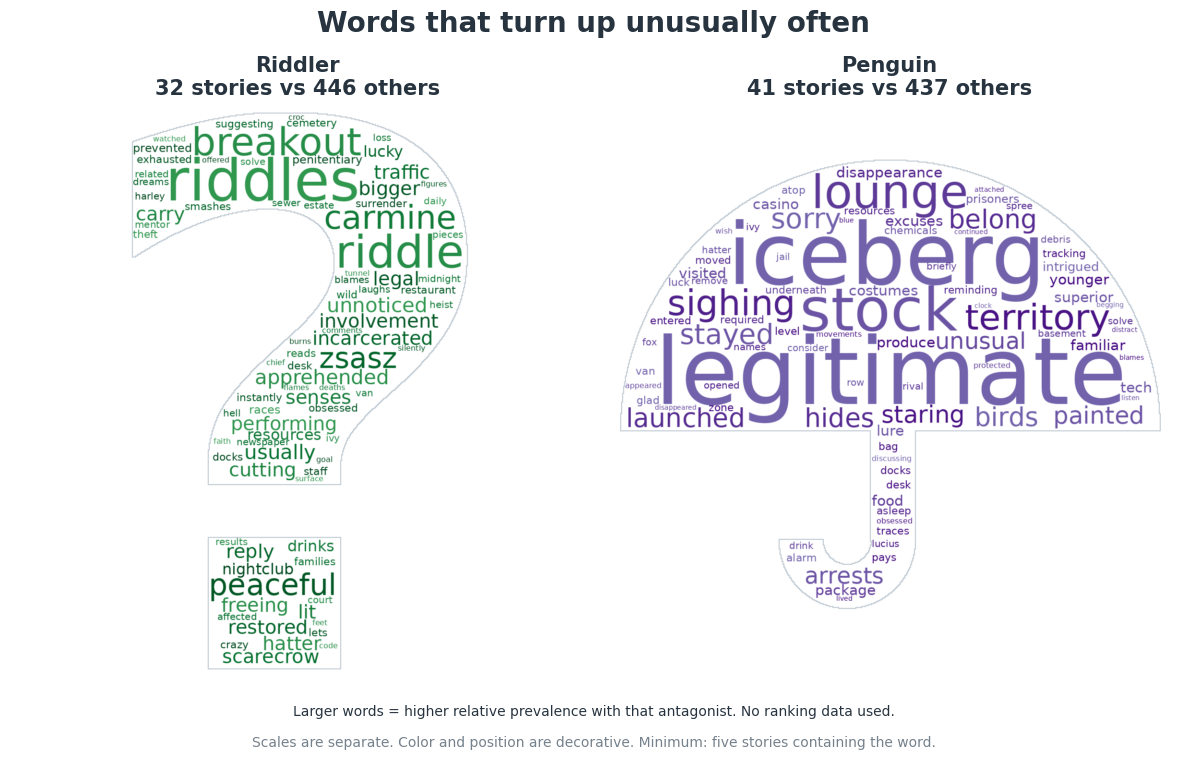

,Antagonist,Word,With this antagonist,Other eligible stories
0,Riddler,riddle,15 / 32,4 / 446
1,Riddler,scarecrow,12 / 32,16 / 446
2,Penguin,legitimate,5 / 41,0 / 437
3,Penguin,iceberg,11 / 41,3 / 437


In [18]:
cloud_stories = s.set_index('story_id').reindex(cloud_docs.story_id)
cast_known = (cloud_stories.cast_scope.eq('selected_narratives')
              & cloud_stories.cast_issue_coverage.eq(1)).to_numpy()
cloud_entities = cloud_stories.antagonists_entity_ids.map(split_set).map(
    lambda values: {re.sub(r' \([^()]+\)$', '', value) for value in values})
cohorts = {
    'Riddler': {'Edward Nashton','Edward Nigma','Edward Nygma','J. Edward Nygma','Riddler'},
    'Penguin': {'Oswald Cobblepot','Penguin'},
}
cloud_tables = []
cloud_members = []
fig,axes = plt.subplots(1,2,figsize=(12,7.8))
for ax,(villain,aliases),palette in zip(axes,cohorts.items(),['Greens','Purples']):
    present = cloud_entities.map(lambda values: bool(values & aliases)).to_numpy() & cast_known
    other = cast_known & ~present
    assert not (present & other).any() and (present | other).sum() == cast_known.sum()
    assert present.sum() >= 5 and other.sum() >= 5
    counts = word_presence[present].sum(axis=0).A1
    other_counts = word_presence[other].sum(axis=0).A1
    score = np.log2(((counts+1)/(present.sum()+2))/((other_counts+1)/(other.sum()+2)))
    table = pd.DataFrame({'villain':villain, 'term':terms,
        'cohort_readings_with_word':counts, 'cohort_readings_total':present.sum(),
        'other_readings_with_word':other_counts, 'other_readings_total':other.sum(),
        'log2_prevalence_ratio':score})
    table = table.loc[(counts >= 5) & (score > 0)].sort_values(
        ['log2_prevalence_ratio','term'], ascending=[False,True]).head(85)
    assert len(table) >= 20 and np.isfinite(table.log2_prevalence_ratio).all()
    cloud_tables.append(table)
    cloud_members.append(pd.DataFrame({'villain':villain,
        'story_id':cloud_docs.loc[cast_known,'story_id'], 'has_antagonist_credit':present[cast_known]}))
    cloud = WordCloud(mask=masks[villain], background_color='white', font_path=font_path,
        random_state=42, max_words=85, scale=2, prefer_horizontal=1,
        colormap=ListedColormap(plt.get_cmap(palette)(np.linspace(.70,.98,8))),
        contour_width=1, contour_color='#BBC6D0').generate_from_frequencies(
            table.set_index('term').log2_prevalence_ratio.to_dict())
    ax.imshow(cloud, interpolation='bilinear')
    ax.axis('off')
    ax.set_title(f'{villain}\n{present.sum()} stories vs {other.sum()} others', fontsize=15)
cloud_terms = pd.concat(cloud_tables,ignore_index=True)
cloud_terms.to_csv(REPORT/'plot_cloud_villain_words.csv', index=False)
pd.concat(cloud_members,ignore_index=True).to_csv(REPORT/'plot_cloud_villain_cohorts.csv', index=False)
fig.suptitle('Words that turn up unusually often', fontsize=20, fontweight='bold')
fig.text(.5,.075, 'Larger words = higher relative prevalence with that antagonist. No ranking data used.',
    ha='center', fontsize=10)
fig.text(.5,.035, 'Scales are separate. Color and position are decorative. Minimum: five stories containing the word.',
    ha='center', fontsize=10, color=COLORS['grey'])
fig.tight_layout(rect=(0,.10,1,.94))
save_figure(fig, REPORT, 'eda-villain-word-clouds')

examples = cloud_terms[((cloud_terms.villain == 'Riddler') & cloud_terms.term.isin(['riddle','scarecrow']))
    | ((cloud_terms.villain == 'Penguin') & cloud_terms.term.isin(['iceberg','legitimate']))].copy()
examples['With this antagonist'] = examples.cohort_readings_with_word.astype(str) + ' / ' + examples.cohort_readings_total.astype(str)
examples['Other eligible stories'] = examples.other_readings_with_word.astype(str) + ' / ' + examples.other_readings_total.astype(str)
display(examples[['villain','term','With this antagonist','Other eligible stories']].rename(
    columns={'villain':'Antagonist','term':'Word'}).reset_index(drop=True))


“Riddle” appears in **15 of 32** Riddler stories, versus **4 of 446** others. “Scarecrow” appears in **12 of 32**, versus **16 of 446**. We catch his company as well as his gimmick.

Penguin gets “iceberg”: **11 of 41**, versus **3 of 437**. “Legitimate” appears in **5 of 41**, versus none of the others. Respectable-looking business is familiar Penguin territory. Here, though, that big word rests on just five stories.

Summary length matters too. Riddler and Penguin summaries have median lengths of **1,422 and 1,200 words**. Both comparison groups have **552**. Longer summaries have more chances to mention any word.

Check the [word counts](../reports/plot_cloud_common_words.csv), [villain comparisons](../reports/plot_cloud_villain_words.csv), and [story lists](../reports/plot_cloud_villain_cohorts.csv). These describe wiki summaries, not the comics' dialogue or prose style.

## What about creator controversy?

The source list records four people and dated events. It distinguishes a conviction from allegations and employment decisions. Here we count only people who worked on the selected story. We exclude covers and unrelated backup stories.

In [19]:
watch = pd.read_csv(ROOT/'data/external/creator_watch.csv')
watch_links = (credits.loc[credits.credit_scope.eq('selected_narrative')]
    .merge(creators[['creator_id','name']], on='creator_id', validate='many_to_one')
    .merge(watch, left_on='name', right_on='creator', validate='many_to_one')
    .merge(s[['story_id','discussion_date']], on='story_id', validate='many_to_one'))
watch_links['discussed_after_recorded_event'] = (
    pd.to_datetime(watch_links.discussion_date) >= pd.to_datetime(watch_links.event_date))
watch_summary = watch_links.groupby(['name','role','event_date'], as_index=False).agg(
    stories=('story_id','nunique'),
    all_discussed_after_event=('discussed_after_recorded_event','all'))
watch_summary['role'] = watch_summary.role.replace({'writers':'Writer','editors':'Editor'})
watch_summary.to_csv(REPORT/'creator_watch_selected_stories.csv', index=False)
display(watch_summary.rename(columns={
    'name':'Creator', 'role':'Role', 'event_date':'Recorded event date',
    'stories':'Stories', 'all_discussed_after_event':'All discussed after event?'}))

,Creator,Role,Recorded event date,Stories,All discussed after event?
0,Eddie Berganza,Editor,2017-11-13,26,True
1,Warren Ellis,Writer,2020-07-13,2,True


Eddie Berganza edited 26 selected stories. Warren Ellis wrote two. All were discussed after the recorded events. There is no before-and-after comparison here. People absent from this short list have not been cleared or systematically reviewed.

## What did we check?

| Possible explanation | Check | What remains unresolved |
|---|---|---|
| Publication era | Rank distributions by decade; villain comparisons within decades. | Readers may prefer particular runs within a decade. |
| Story length | Villain comparisons within issue-count bands; team stability within arc lengths. | One issue can contain eight pages or a full graphic novel. |
| Large casts | Named characters and their stories are shown together. | A brief appearance and a central role do not carry equal weight. |
| Recurring partnerships | Writer–artist pairs and their rank ranges. | This cannot separate the contribution of art from writing. |
| Incomplete summaries | Plot coverage by decade; word analyses use complete available summaries. | Wiki summaries differ in length and detail. |
| Creator controversy | Selected-story roles and event dates. | No comparable pre-event rankings or fully reviewed control group. |

These are comparisons within BatChat's selections. They do not estimate what causes a story to rank higher.

## Three comparisons worth reading

- **Red Rain and Unseen:** the same writer and artist, 710 ranking places apart.
- **Unknowing, Madness, and Mad:** Hatter-centered stories that test what his high median conceals.
- **Undone and The Clown at Midnight:** silence beside illustrated prose, in almost the same page count.

[Can we predict the rankings?](1.0-batchat-rankings.ipynb) · [Where do other readers disagree?](3.0-batchat-versus-the-crowd.ipynb) · [Data dictionary](../references/data_dictionary.md)